<a href="https://colab.research.google.com/github/SRXKaiser/analitica-de-datos/blob/main/Practicas%20U3/Practias_Finales_de_Equipo/Actividad_Serie_De_Tiempo_Practica_de_Equipo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Practica de Equipo 3**

# * Nombre y numero de control
- Víctor Manuel Landeros Ramírez - 2311
- Karely Pérez Vargas – 23111441
- Diego Pulido Hernández – 22111487

#### **En esta actividad trabajarás con datos históricos del precio de mercado de la acción de alguna de las grandes compañías como Nvidia, Tesla, Google.**

Sigue los siguientes pasos para descargar los datos del problema:

    Ir a la página de Yahoo!-Finance: https://finance.yahoo.com/

En el buscador de dicha página pon las iniciales de la compañía deseada. Deberás seleccionar alguna de las siguientes compañías: AAPL, NVDA, TSLA, GOOG, AMZN o MSFT.

Seleccionar la pestaña "Historical Data".

Pulsa "Download" para descargar el archivo de datos históricos de los movimientos diarios de los últimos 5 años.



# **En esta Actividad se trabajará con los datos historicos del precio de mercado de la acción, Compañia NVDA.**

# **0 - Preparando los datos ORIGINALES**

In [ ]:
# Omitamos los Warnings por el momento:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
!pip freeze   # Si deseas verificar qué librerías y versiones ya tiene google-Colab preinstaladas,
               # en particular "prophet" que usaremos en este ejercicio.

absl-py==2.0.0
accelerate==1.15.0
access==1.1.10.post3
affine==3.0.1
aiofiles==25.1.0
aiohappyeyeballs==2.7.1
aiohttp==3.14.5
aiosignal==1.4.0
aiosqlite==0.22.1
alabaster==1.0.0
albucore==0.0.24
albumentations==2.0.8
ale-py==0.12.1
altair==5.5.0
annotated-doc==0.0.5
annotated-types==0.8.0
anyio==4.16.0
anywidget==0.9.21
apsw==3.54.1.0
argon2-cffi==25.1.0
argon2-cffi-bindings==26.1.0
array_record==0.8.6
arrow==1.4.0
arviz==0.22.0
astropy==7.2.3
astropy-iers-data==0.2026.11.2.0.34.55
astunparse==1.6.3
atpublic==5.1
attrs==26.1.0
audioop-lts==0.2.2
audioread==3.1.0
Authlib==1.9.3
autograd==1.9.1
babel==2.18.0
backcall==0.2.0
beartype==0.23.1
beautifulsoup4==4.13.5
betterproto==2.0.0b7
bigframes==2.51.0
bigquery-magics==0.14.0
bleach==6.4.0
blinker==1.9.0
blis==1.3.4
blobfile==3.3.0
blosc2==4.14.1
bokeh==3.8.2
Bottleneck==1.4.2
bqplot==0.12.47
branca==0.8.2
brotli==1.2.1
CacheControl==0.14.4
cachetools==6.2.6
catalogue==2.0.10
certifi==2026.10.23
cffi==2.1.1
chardet==5.2.0
charset-normaliz

In [ ]:
!pip install yfinance

In [ ]:

#Libreria para obtener el conjunto de datos
import yfinance as yf

#Para manipular datos
import numpy as np
import pandas as pd

#Para graficar
import matplotlib.pyplot as plt

#Error cuadratico medio
from sklearn.metrics import mean_squared_error
import math

#Para aplicar escalamiento de datos [0,1]
from sklearn.preprocessing import MinMaxScaler

from prophet import Prophet
from statsmodels.graphics.tsaplots import month_plot, quarter_plot
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf   # gráficos de autocorrelación

#A) **Descargar el archivo de datos históricos de los movimientos diarios de los últimos 5 años.**

In [ ]:
#Escribimos las iniciales de la compañia con la que deseemos trabajar. En esta ocasión trabajare con Tesla

ticker_symbol = 'NVDA'                           # selecciona las iniciales de la compañía deseada.
#data = yf.download(ticker_symbol, period='5y')   # Se indica el período de 5 años y descargamos.

#segunda forma, ya que no se esta incluyendo la columna de date en el df descargado
#definirn el rango de fechas a descargar (5 años)
start_date = "2021-11-17"
end_date = "2026-11-17"

#convierte a dataframe
#auto_adjust=False para incluir adj close
df = yf.download(ticker_symbol, start=start_date, end=end_date, auto_adjust=False)   #header=2 para que no tome en cuenta los 2 primeros renglones, ya que estan vacios
#df.columns=['Date','Adj Close','Close','High','Low','Open','Volume'] #Se agrega columna Date


#esta cosa si es importante, sirve para quitar el multiindex, osea solo quede una fila de encabezados
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)
df.columns.name = None
df =df.reset_index()

df.head()


[*********************100%***********************]  1 of 1 completed


,Date,Adj Close,Close,High,Low,Open,Volume
0,2021-11-17,29.132681,29.261000,30.509001,28.799999,30.417999,428508000
1,2021-11-18,31.536097,31.674999,32.759998,31.320999,32.367001,781711000
2,2021-11-19,32.840359,32.985001,33.088001,31.905001,32.243000,533867000
3,2021-11-22,31.815863,31.955999,34.646999,31.900000,33.516998,754335000
4,2021-11-23,31.606783,31.746000,32.360001,30.879999,31.535000,532163000


In [ ]:
df.info()   # Verifica detalles del conjunto de datos a utilizar
            # El dataframe cuenta con 1258 registros
            # 7 columnas las cuales son: Date, Adj close, Close, High, Low, Open, Volume
            # Variable Date, tipo Object -> se cambiará a tipo Fecha

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1254 entries, 0 to 1253
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       1254 non-null   datetime64[ns]
 1   Adj Close  1253 non-null   float64       
 2   Close      1253 non-null   float64       
 3   High       1254 non-null   float64       
 4   Low        1254 non-null   float64       
 5   Open       1254 non-null   float64       
 6   Volume     1254 non-null   int64         
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 68.7 KB


#**B)Utiliza solamente los datos de la columna "Adj Close" en esta actividad.**

In [ ]:
# Renombremos de manera estándar las columnas de fechas y valores de la
# serie de tiempo, donde además la fecha la trasnformamos a tipo datetime:

df = df.drop(columns=['Close','High','Low','Open','Volume']) #Elimina columnas que no se requieren
df = df.rename(columns={'Adj Close':'y'})                    #Columna Adj Close, renombramos por y
df['Date'] = pd.to_datetime(df['Date'])                      #Convertimos variable Date de tipo Object a Datetime
df.head()                                                    #Muestra primeros 5 registros para visualizar el cambio

,Date,y
0,2021-11-17,29.132681
1,2021-11-18,31.536097
2,2021-11-19,32.840359
3,2021-11-22,31.815863
4,2021-11-23,31.606783


In [ ]:
df.info() #Creación de un nuevo df, el cual consta de 2 columnas, las cuales son:
          #Variable Date -> de tipo datetime64, nos ayuda a representar un rango de fechas muy amplio con presición nanosegundos
          #Variable 'Adj Close' -> fue renombrada por 'y' de tipo flotante,

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1254 entries, 0 to 1253
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    1254 non-null   datetime64[ns]
 1   y       1253 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 19.7 KB


En particular datetime64[ns] nos ayuda a representar un rango de fechas muy amplio con precisión de nanosegundos.

### **Agreguemos los ajustes usuales en Series de tiempo:**

In [ ]:
# Hagamos una copia del DataFrame df con índices temporales:

df_temp = df.copy()                     #Genera copia del df originar en nueva variable temporal de nombre: df_temp
df_temp.set_index('Date', inplace=True) #se establece como indice Variable Date,
                                        #parametro inplace=True, es para guardar los cambios
df_temp.head()                          #visualizar los cambios

,y
Date,
2021-11-17,29.132681
2021-11-18,31.536097
2021-11-19,32.840359
2021-11-22,31.815863
2021-11-23,31.606783


In [ ]:
#Muestra información sobre numero total de registros y columnas como estan conformados el df original (df) y el df temporal (df_temp)

print("DataFrame Original:\n ")
print(df.shape)      #Conformado por 1258 registros y 2 columnas (Date, y)

print("\nDataFrame Temporal:\n")
print(df_temp.shape) #Conformado por 1258 regsitros y 1 columna (y), Variable Date pase a ser indice

DataFrame Original:
 
(1254, 2)

DataFrame Temporal:

(1254, 1)


https://pandas.pydata.org/docs/reference/api/pandas.DatetimeIndex.html

In [ ]:
# Ajustemos la frecuencia de los índices, para que el modelo tenga información del período en que
# se encuentran los datos:

df_temp.index =df_temp.index.tz_localize(None) #Para quitar zona horaria
df_temp.index


DatetimeIndex(['2021-11-17', '2021-11-18', '2021-11-19', '2021-11-22',
               '2021-11-23', '2021-11-24', '2021-11-26', '2021-11-29',
               '2021-11-30', '2021-12-01',
               ...
               '2026-11-03', '2026-11-04', '2026-11-05', '2026-11-06',
               '2026-11-09', '2026-11-10', '2026-11-11', '2026-11-12',
               '2026-11-13', '2026-11-16'],
              dtype='datetime64[ns]', name='Date', length=1254, freq=None)

-----------------------------------------------------------------------------
**Se puede observar que la ejecución se esta línea de código indica 'freq=None', por lo cual tendremos que definir un tipo de frecuencia (ya sea por dias, meses, años). La cual se definirá en el siguiente segmento de código que se muestra a continuación:**

-----------------------------------------------------------------------------

Para las opciones de "freq" ver la tabla que viene en esta liga:

https://pandas.pydata.org/pandas-docs/stable/user_guide/timeseries.html#offset-aliases

In [ ]:
# Especifiquemos entonces que nuestros datos están registrados con una frecuencia mensual
# al inicio del mes (cada día 01 de cada mes):

#se quedara la frecuencia B de dias habiles
df_temp = df_temp.resample('B').asfreq()#Define frecuencia B -> frecuencia del día de actividad
df_temp.index

DatetimeIndex(['2021-11-17', '2021-11-18', '2021-11-19', '2021-11-22',
               '2021-11-23', '2021-11-24', '2021-11-25', '2021-11-26',
               '2021-11-29', '2021-11-30',
               ...
               '2026-11-03', '2026-11-04', '2026-11-05', '2026-11-06',
               '2026-11-09', '2026-11-10', '2026-11-11', '2026-11-12',
               '2026-11-13', '2026-11-16'],
              dtype='datetime64[ns]', name='Date', length=1304, freq='B')

#**C)Investiga el significado de esta columna Adj-Close e inclúyelo en tu reporte del Jupyter-Notebook.**

###Investigación

-------------------------------------------------------------------------
¿Qué es el Cierre Ajustado?

Adj Close es una columna Clave dentro de los datos historicos . El **Precio Ajustado de cierre**, se apoya de dividendos y splist de acciones, que afectan el precio de la acción.

Es una versión ajustada del Precio de Cierre de una acción, después de los ajustes para todas las distribuciones de splits y dividendos aplicables, los cuales se definen a continuación:

 * **Dividendos**, Aqui es cuando la empresa distribuye dividendos a sus accionistas. El dividendo se "resta" del precio de la acción para representar el valor real de la acción después del pago realizado.

* **Splits(Divisiones de Acciones)**, Aqui es cuando el precio de la acción se ajusta para reflejar la nueva cantiad de acciones en circulación. Aumenta el número de acciones de circulación, pero la capitalización no cambia


##Importancia del Adj Close

El Adj Close, es muy importante ya que gracias a el se puede visualizar de mejor la manera la evolución del valor de la acción que se ha tenido a lo largo del tiempo. Siendo muy útil al momenteo de realizar análisis de rendimiento y asi lograr obtener una visipon más clara de cómo se ha comportado una acción dentro del mercado por un periodo de tiempo

De igual manera también es muy útil para realizar cálculos más precisos, si se desea cálcular el rendimiento total de una acción o retornos de una inversión en un cierto periodo, ya que por otro lado si se hace uso unicamente de "close" sin el ajuste, puede existir sesgo en el análisis.

--------------------------------------------------------------------

##**Respuesta propia**

Es el precio de cierre de una acción modificado para acciones corporativoas como divisiones de acciones, dividendos y ofertas de derechos para reflejar con precisión su valor.
Esta ayuda a los inversores a evaluar el rendimiento histórico de las acciones y comparar la rentabilidad de diferentes activos de forma mas eficaz.

El principal beneficio del cierre ajustado es que ayuda a evaluar el rendimiento de las acciones, mostrando a los inversores las gananciaas potenciales de un activo.

--------------------------------------------------------------------

#**D)Divide los datos en Train y Test, donde Test serán los últimos 20 precios de mercado de la compañía que seleccionaste**

In [ ]:
df_temp=df_temp.ffill() #para rellenar datos faltantes NaN
datos_nan=df_temp[df_temp.isna().any(axis=1)] #para verificar existencia datos faltantes
#print(datos_nan)

In [ ]:
# Particionemos en entrenamiento y prueba como DataFrames de Pandas:
train = df_temp.iloc[0:-20,:] # Selecciona todos los registros, excepto últimos 20
test = df_temp.iloc[-20:,:]   # Seleccionamos los datos del últimoS 20 registros para predicción de Test.

In [ ]:
test.head()  #muestra registros del test

,y
Date,
2026-10-20,216.470001
2026-10-21,221.970001
2026-10-22,212.210007
2026-10-23,210.960007
2026-10-26,216.000000


In [ ]:
datos_nan=train[train.isna().any(axis=1)]
print(datos_nan) #verificamos que no existan datos faltantes NaN en Entrenamiento (train)

datos_nan=test[test.isna().any(axis=1)]
print(datos_nan) #verificamos que no exista datos faltantes NaN en Pueba (test)

Empty DataFrame
Columns: [y]
Index: []
Empty DataFrame
Columns: [y]
Index: []


In [ ]:
train.shape #Entrenamiento conformado por 1284 registros y 1 columna

(1284, 1)

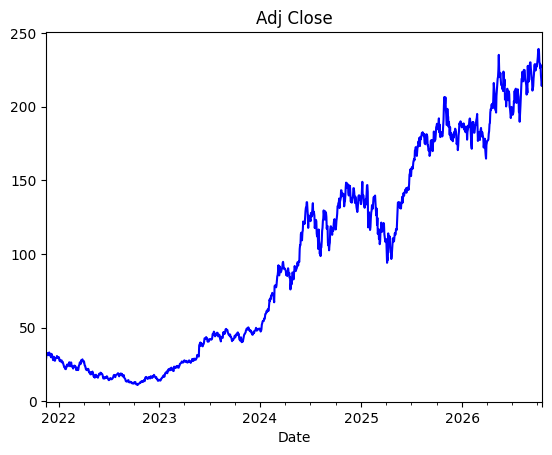

In [ ]:
# Gráfico con la periodicidad anual:
train['y'].plot(title='Adj Close', style='-b')
plt.show()

## <font color=orange>**Escriba su Interpretación de la gráfica**</font>





## <font color=orange>**De este gráfico podemos observar:**

1. Gráfica realizada con los datos de entrenamiento

2.    Se puede observar un crecimiento del cierre ajustado a lo largo de los años.

3. Durante el 2022, el precio de cierre se mantenia entre los 0 y 50, y decayo de forma gradual.

4. Durante el 2023, observamos como el precio de cierre se disparo con gran rapidez, alcanzando casi el valor de 150 a mediados de 2024. Un crecimiento el doble de rápido en comparacion al decaeimiento del 2023

5. Durante el primer tercio del 2025, observamos como el precio ajustado vuelve a decaer, sin embargo no regresa a los primeros valores tan bajos como en el 2023, sino que es una caida menor.

6. En la segunda mitad del 2025, observamos como el cierre ajustado vuelve a dispararse, sobrepasando el valor de 150, a partir de aqui tendra un crecimiento paulatino, donde tendrá unas constantes altas y bajas, pero siempre volviendo a crecer más.



# **1 - Modelo ingenuo (Baseline / Persistance / Naive model)**

# **DATOS ORIGINALES**

*   El modelo ingenuo simplemente **hace la predicción del siguiente período, repitiendo el valor del último período**.

*   Este modelo se utiliza en general como punto de partida **para comparar todos los demás**.

*   Utilicemos el error RMSE (Raíz del Error Cuadrático Medio) como medida del desempeño de nuestros modelos a obtener.

In [ ]:
test['y'].values #muestra valores del conjunto test en arreglo

array([216.47000122, 221.97000122, 212.21000671, 210.96000671,
       216.        , 217.94000244, 215.38000488, 213.66000366,
       204.63999939, 202.05999756, 206.69000244, 200.13000488,
       181.6000061 , 186.63999939, 178.66999817, 168.88999939,
       173.72999573, 166.19000244, 162.8500061 , 162.8500061 ])

In [ ]:
history = [x for x in train['y'].values]   # Definimos "history" donde de manera incremental se irán agregando registros mensuales.
predictions = list()    # Lista que contendrá las predicciones del modelo ingenuo.

for i in range(len(test['y'])):
  # Obtenemos las predicciones:
  yhat = history[-1]   # La primera vez, tomamos el último dato del Train, en las siguientes, se van agregando los datos de Test.
  predictions.append(yhat)

  # Observaciones-registros reales:
  obs = test.iloc[i]['y']   # Ahora vamos tomando los datos de Test.
  history.append(obs)  # Vamos agregando a "history" (que ya tiene todo los de Train) en cada iteración, un dato más de los de Test.
  print('>Esperado-real = %3d, Predicción = %.3f' % (obs, yhat))


# Calculamos la raíz del error cuadrático medio (RMSE):
rmse = np.sqrt(mean_squared_error(test['y'].values, predictions))
print('\nError-Modelo-Naive: RMSE: %.3f' % rmse)

>Esperado-real = 216, Predicción = 217.090
>Esperado-real = 221, Predicción = 216.470
>Esperado-real = 212, Predicción = 221.970
>Esperado-real = 210, Predicción = 212.210
>Esperado-real = 216, Predicción = 210.960
>Esperado-real = 217, Predicción = 216.000
>Esperado-real = 215, Predicción = 217.940
>Esperado-real = 213, Predicción = 215.380
>Esperado-real = 204, Predicción = 213.660
>Esperado-real = 202, Predicción = 204.640
>Esperado-real = 206, Predicción = 202.060
>Esperado-real = 200, Predicción = 206.690
>Esperado-real = 181, Predicción = 200.130
>Esperado-real = 186, Predicción = 181.600
>Esperado-real = 178, Predicción = 186.640
>Esperado-real = 168, Predicción = 178.670
>Esperado-real = 173, Predicción = 168.890
>Esperado-real = 166, Predicción = 173.730
>Esperado-real = 162, Predicción = 166.190
>Esperado-real = 162, Predicción = 162.850

Error-Modelo-Naive: RMSE: 6.848


----------------------------------------------------------------------------
## <font color=orange>**Interpretación**


-----------------------------------------------------------------------------

Para este modelo, se puede ver que la predicción no estaba muy alejada del siguiente valor real.
Con un error cuadratico medio de 6.84, este modelo solo se estuvo equivocando por 6 unidades en promedio, pero en varias ocasiones, se esquivocaba por 3 o menos unidades, se observo que este rango se iba haciendo mas pequeño a medida que se acercaba al valor real.

Este sirvio como base de comparacion para los siguientes modelos que seran mas complejos, esto con un volumen de datos no tan grande (el conjunto de datos de entrenamiento) ni usar un procesamiento complejo.

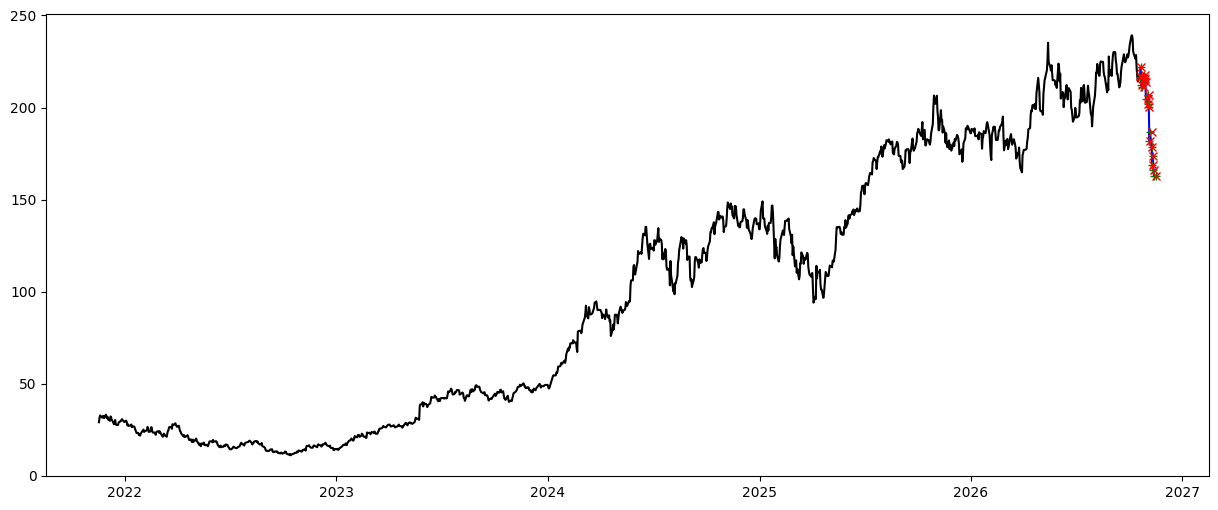

In [ ]:
# Grafiquemos los resultados:

fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train['y'], '-k')   # Datos de entrenamiento (los históricos).
ax = plt.plot(test['y'], '-b')    # Datos de prueba reales (los últimos 20 registros a predecir).
ax = plt.plot(test['y'],'+g')
ax = plt.plot(test.index, predictions, 'xr')  # Predicciones del modelo ingenuo.

#Verdes son los datos reales
#rojos son las predicciones

### <font color=orange>**Interpretación Gráfica.**

----------------------------------------------------------------------------
Podemos ver que el modelo complejo es muy eficaz cuando se usa un volumen de datos no tan grande, ya que estos valores que arrojo de predicciones, son muy parecidos a los valores reales que se usaron en el entrenamiento.

Observando primero esta curva que decae ligeramente a lo largo de 2023.

Despues el cierre ajustado disparado hasta 2025, seguido de la pequeña caida en el primer tercio de este año.

Terminamos con el crecimiento paulatino, donde observamos que cae y sube este valor, sin observar alguna caida significativa, ya que simepre se mantiene por encima de 150.

----------------------------------------------------------------------------

# **2 - Modelo ARIMA**

# **DATOS ORIGINALES**

### **Análisis preliminar para obtener información de la serie de tiempo y construir el modelo ARIMA(p,d,q).**

*   **AR (AutoRegresivo):** El modelo se basa en la **relación entre un valor actual y sus valores pasados.**

*   **I (Integrado):** Se refiere a la diferenciación de la serie para hacerla estacionaria, es decir, eliminar tendencias y patrones cíclicos.

*   **MA (Media Móvil):** Usa el error de los valores pasados (las desviaciones entre valores predichos y observados) para corregir el valor actual.

##### **Ahora veamos el gráfico de descomposición de la serie de tiempo en sus componentes de tendencia (trend), estacionalidad (stationality) y residual (residual).**

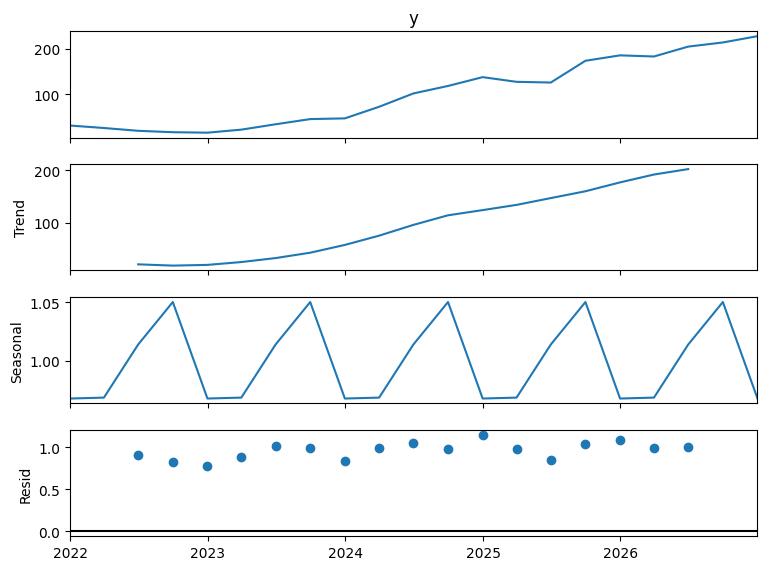

In [ ]:
# Gráficos de descomposición estacional:
#parametro Q indica año
decomposition = seasonal_decompose(train['y'].resample('Q').mean(), model='multiplicative')  # <<<---- Observa que el modelo es multiplicativo
fig = decomposition.plot()
fig.set_size_inches(8,6)
plt.show()

# <font color=orange>**Interpretación de cada una de las Gráficas**

-----------------------------------------------------------------------------

En esta gráfica nos desgloza 4 gráficas:

1. **Gráfica Original**: se puede observar el mismo comportamiento que en las gráficas de los datos originales y el modelo ingenuo. Ya se explico este comporamiento en las interpretaciones de las gráficas mencionadas, por lo que no se mencionara aqui, pero es evidente la similitud entre los modelos.

2. **Tendencia (Trend)**: Se puede observar una tendncia alcista, donde existen leves rangos en el que la barra baja, pero nunca más de lo que sube.

3. **Estacional (Seasonal)**: Se puede observar una evolución muy constente, el comportamiento de esta gráfica es:
  mentenerse en el punto mas bajo de forma constante, subir de golpe hasta el punto mas alto y volver a bajar hasta el punto mas bajo con la misma rápidez. Este comportamiento se sigue repitiendo una y otra vez.

4. **Residuos (Resid)**: se puede observar un patron de una curva que sube y baja constantemente manteniendose dentro de un rngo, a veces la curva esta mas baja, mas arriba o abarca mas rango, sin embargo, este no es muy grande. el rango de esta grafica se encuentra entre 0.5 y 1.

-----------------------------------------------------------------------------

##### **Veamos ahora estos dos gráficos que nos hablan si tenemos algún tipo de estacionalidad (i.e., periodicidad). En particular, mensual o trimestral:**

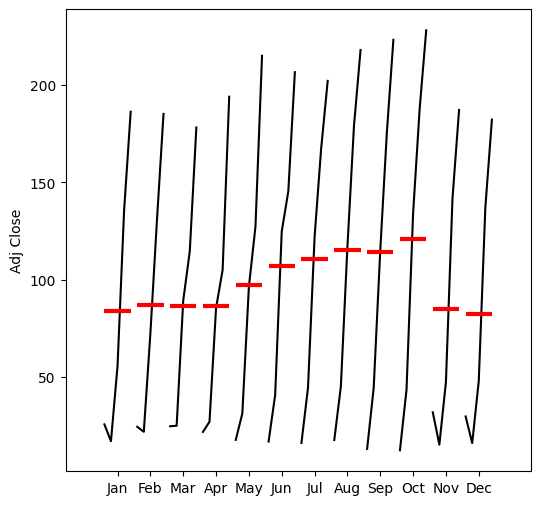

In [ ]:
# Gráfica para detección de estacionalidad mensual:
fig = month_plot(train['y'].resample('M').mean(), ylabel='Adj Close')
fig.set_size_inches(6,6)
plt.show()

# <font color=orange>**Interpretación Gráfica**

-----------------------------------------------------------------------------
Esta gráfica muestra los datos del ajuste de cierre por el perido fijo del mes. Esto es util para poder comparar el comportamiento de cada mes con otro de una forma visual mas limpia.

Podemos observar menos datos graficados y aun asi poder identificar el comportamiento de cada mes al igual que con cualquiera de las gráficas anteriores porque lo que hace el gráfico de deteccion de estacionalidad es definir un valor promedio para cada mes, resumiendo una grafica que tiene un dato por cada dia, a solo uno por mes durante un año.



----------------------------------------------------------------------------

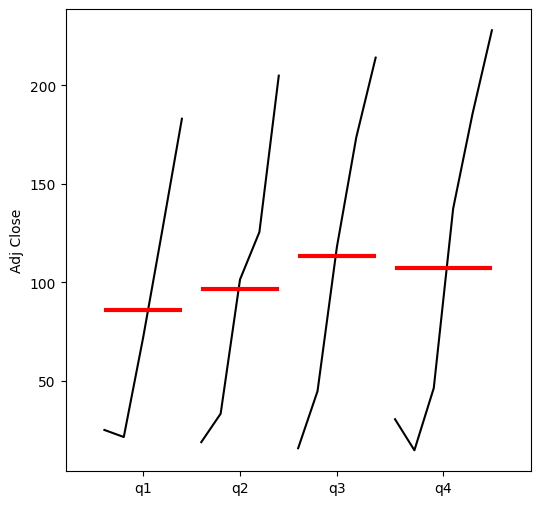

In [ ]:
# Si queremos graficar y detectar estacionalidad trimestral:
fig = quarter_plot(train['y'].resample('Q').mean(), ylabel='Adj Close')
fig.set_size_inches(6,6)
plt.show()

# <font color=orange>**Interpretación Gráfica**

----------------------------------------------------------------------------
Ese gráfico muestra la misma información que el gráfico anterior, pero de una manera aun más resumida. Mostrando el comportamiento de los datos de forma trimestral, pasando de mostrar 12 datos a solo 4.
Esto perosnalmente vuelve un poco mas complicada la lectura de los datos, ya que queda mas ambiguo cual es el comportamiento detallado, sin embargo, aun es posible concluir que durante este año, los datos se comportaron primeramente, con una tendencia ascendente ligera, y comenzo a bajar en el ultimo trimestre



----------------------------------------------------------------------------

### **Gráficos de Autocorrelación (ACF) y Autocorrelación Parcial (PACF)**

*   Los gráficos de Autocorrelación miden la correlación entre la serie de tiempo y una versión rezagada de sí misma.

*   Este tipo de correlaciones de una serie de tiempo consigo misma son llamadas "autocorrelaciones" o "correlaciones seriales".

*   En el eje horizontal se muestra el valor del desfazamiento (lag) y en el eje vertical el valor de correlación de la serie desfazada y la original.

*   El cono sombreado indica intervalos de confianza de la correlación, con un 95% de confianza de manera predeterminada.

*   Que existan autocorrelaciones significativas en estos gráficos nos habla de que la serie de tiempo no es aleatoria.

*   En estos dos gráficos (llamados en inglés "pollipop plots") hay que determinar cuántos de estos lollipops están afuera del intervalo de confianza (sin contar el inicial) antes de que entre el siguiente a la zona celeste?

*   **Gráfico ACF:** Muestra la correlación total entre la serie y sus retardos, incluyendo efectos directos e indirectos.

*   **Gráfico PACF:** Muestra la correlación directa entre la serie y sus retardos, eliminando los efectos de los retardos intermedios.

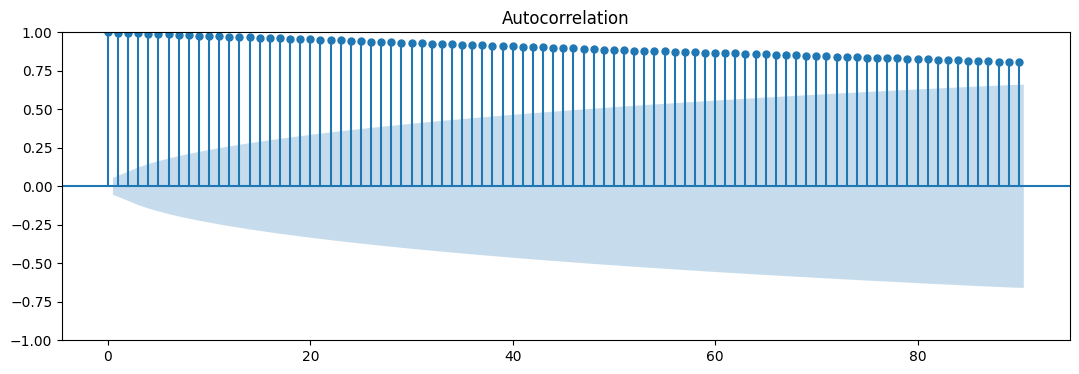

In [ ]:
# Gráfico de Autocorrelación (ACF: Auto-Correlation-Function)
train['y'] = train['y'].ffill() ##Rellenan campos que estan NaN
fig,ax = plt.subplots(figsize = (13,4))
plot_acf(train['y'], lags=90, ax=ax)   # Eliges el número de unidades (meses) desfasadas. El número de "lags" es el número
plt.show()

# <font color=orange>**Intepretación Gráfica Autocorrelación (ACF)**

-----------------------------------------------------------------------------

El coeficiente es alto en el retraso basicamente durante la mayoria del grafico, notandose  un desfazamiento elevado, existe una alta correlacin para los valores de la primera mitad del gráfico. Para la segunda mitas, se puede observar como poco a poco va haciendo mas pequeño el retraso, sin embarco, nunca desaparece por completo.


-----------------------------------------------------------------------------

El gráfico inicia con desfase (lag) de 0, lo cual es la correlación de la serie de tiempo consigo misma, la cual es 1.

Posteriormente se muestran las correlaciones de la serie de tiempo original, con la serie desfasada "q" lugares hacia atrás, es decir, de orden "q" en la componente MA de ARIMA(p,d,q).

**El gráfico ACF nos dice en primera instancia que la componente MA de ARIMA(p,d,q) tiene un grado "q" de 13 (en la práctica se puede buscar de 0 a 13).**

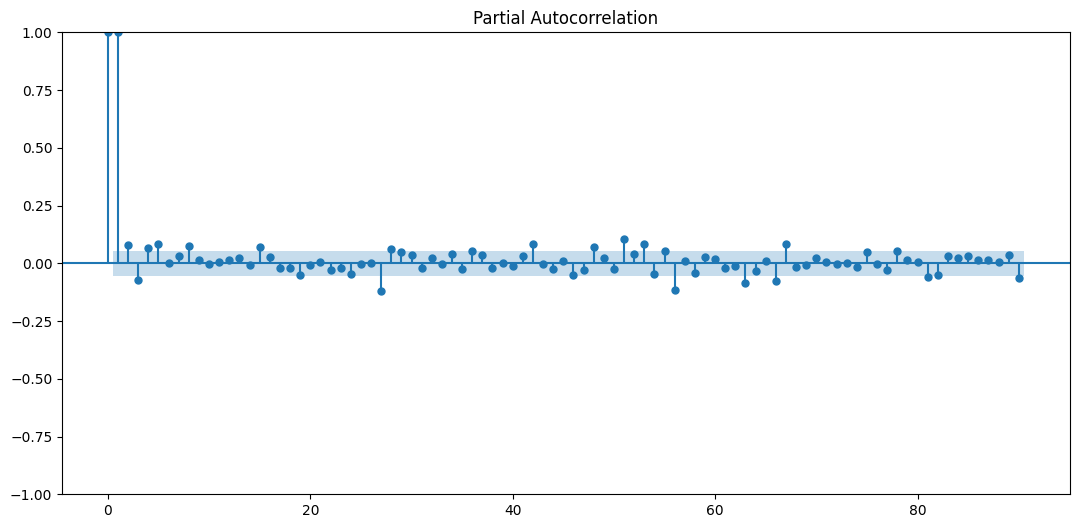

In [ ]:
# Gráfico de Autocorrelación Parcial (PACF):
fig, ax = plt.subplots(figsize = (13,6))
plot_pacf(train['y'], lags = 90, ax = ax, method="ols")   # ols: regression of time series on lags of it an on constant. predetrminado method="ywm"
plt.show()

# <font color=orange>**Interpretación Gráfica Partial Autoccorelation (PACF)**

----------------------------------------------------------------------------

En esta gráfica, existe una correlción relativa en el desfase 1 y 2. despues de estas, le siguen correlaciones minimas o incluso no significativas. Este gráfico muestra un término autoregresivo en los datos.

----------------------------------------------------------------------------

* PACF también inicia con la correlación de la serie de tiempo consigo misma, por ello el valor de 1.

*   **De este gráfico podemos observar que la componente AR de ARIMA(p,d,q) tiene grado p=3 o tal vez 5 (en la práctica se puede probar de 0 a 5.)**

##### Existe un buen número de librerías para el caso de pronósticos con los modelos ARIMA-SARIMA. Usaremos en este ejercicio la de Statsmodels, cuya documentación encuentras en la siguiente liga:

https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html

In [ ]:
from statsmodels.tsa.arima.model import ARIMA

In [ ]:
# Lo primero es para quitar la estacionalidad y transformar un problema
# de tipo no-estacionario (SARIMA) en uno estacionario (ARIMA):

# Diferencia de datos consecutivos en el tiempo
# y podemos ahora usar ARIMA:
def difference(dataset, interval=1):
  diff = list()

  for i in range(interval, len(dataset)):
    value = dataset[i] - dataset[i - interval]
    diff.append(value)

  return np.array(diff)



# Invierte las diferencias anteriores, es decir, nos regresa la estacionalidad:
def inverse_difference(history, yhat, interval=1):
  return yhat + history[-interval]


In [ ]:
# Definamos la siguiente lista de registros de pasajeros en el tiempo:
history = [x for x in train.loc[:,'y'].values]   # train-ndarray : columna solo con los registros de pasajeros "y".
                               # history-list : lista con los datos del train.

predictions = list()   # Para incluir las predicciones que vaya generando el modelo.

for i in range(len(test['y'])):
  #
  months_in_year = 12
  diff = difference(history, months_in_year)    # diff-list: lista de los datos de diferencias para transformar SARIMA en ARIMA.

  # Generamos el modelo.    (p,d,q)  p->valor definido en gráfica partial autocorrelation  d->Estacionaria  q->valor definido en grafica autocorrelacion
  model = ARIMA(diff, order=(1,0,13),) # Si aplicamos diff, entonces d=0 es aplicable.
  model_fit = model.fit(method_kwargs={'maxiter':300})  # Aumentar las iteraciones para evitar el WarningConvergence.

  yhat = model_fit.forecast()[0]   # prediccions (yhat) de cada registro, es un solo número flotante.
  yhat = inverse_difference(history, yhat, months_in_year)    # El "history" sigue siendo la lista de arriba.
                                                              # El nuevo "yhat" es cada un nuevo valor (float) de predicción.
  predictions.append(yhat)  # predictions-list : lista que se va incrementando al ir agregando cada predicción nueva.

  # Observaciones-reales:
  obs = test.iloc[i]['y']   #  cada dato es un flotante.
  history.append(obs)   #  history-list : se va incrementado a partir del Train con los registros-observaciones reales.

  print('>Esperado-real = %3d, Predicción = %.3f' % (obs, yhat))

# Error RMSE:
rmse = np.sqrt(mean_squared_error(test['y'].values, predictions))
print('\nError-Modelo-ARIMA: RMSE: %.3f' % rmse)

>Esperado-real = 216, Predicción = 218.641
>Esperado-real = 221, Predicción = 217.154
>Esperado-real = 212, Predicción = 222.533
>Esperado-real = 210, Predicción = 213.229
>Esperado-real = 216, Predicción = 211.307
>Esperado-real = 217, Predicción = 215.653
>Esperado-real = 215, Predicción = 217.192
>Esperado-real = 213, Predicción = 216.259
>Esperado-real = 204, Predicción = 213.665
>Esperado-real = 202, Predicción = 205.156
>Esperado-real = 206, Predicción = 203.265
>Esperado-real = 200, Predicción = 207.196
>Esperado-real = 181, Predicción = 202.197
>Esperado-real = 186, Predicción = 183.578
>Esperado-real = 178, Predicción = 187.859
>Esperado-real = 168, Predicción = 179.760
>Esperado-real = 173, Predicción = 169.784
>Esperado-real = 166, Predicción = 173.591
>Esperado-real = 162, Predicción = 166.415
>Esperado-real = 162, Predicción = 164.071

Error-Modelo-ARIMA: RMSE: 7.247


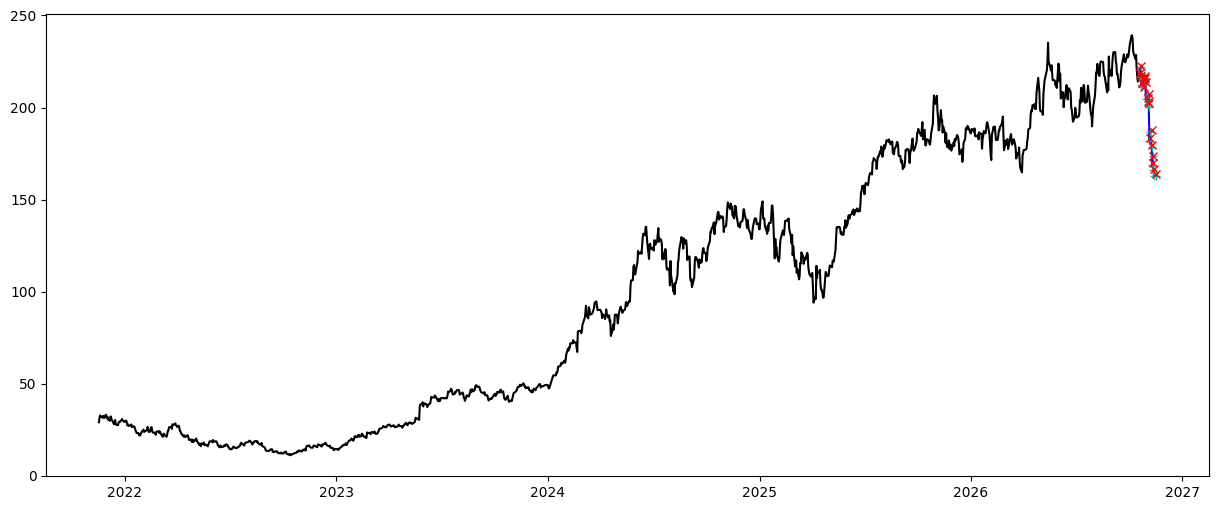

In [ ]:
# Veamos su gráfico de ARIMA:
fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train['y'], '-k')
ax = plt.plot(test['y'], '-b')
ax = plt.plot(test['y'], '+c')
ax = plt.plot(test.index, predictions, 'xr')

### <font color=orange>**Interpretación Gráfica ARIMA**</font>

-----------------------------------------------------------------------------
En este gráfico podemos observar que este modelo logra predecir la tendencia del ajuste de cierre de los siguente 20 dias de una forma que se ve lógica y posible.

* Las predicciones hechas para este modelo siguen de forma casi idéntica las fluctuaciones y la dirección de los datos reales que se apartaron para las pruebas ( la línea azul).
* El comportamiento de este modelo es increiblemente dinámico a comparación con el modelo ingenuo,porque este no se limita a seguir un retraso simple, sino que reacciona a los choques de corto plazo gracias a componententes autorregresivas y de media móvil, obteniendo un RMSE DE 7.2.
----------------------------------------------------------------------------

# **3 - Modelo Facebook-Meta-Prophet**

# **DATOS ORIGINALES**

#### **En la liga del modelo Facebook-Prophet puedes encontrar mucho más información, además de la documentación correspondiente:**

https://facebook.github.io/prophet/

In [ ]:
df_temp.head() #verificar que el df_temp este en formato correcto

,y
Date,
2021-11-17,29.132681
2021-11-18,31.536097
2021-11-19,32.840359
2021-11-22,31.815863
2021-11-23,31.606783


In [ ]:
# Prophet requiere que la entrada sean dos columnas, llamadas "ds" y "y".
# Les dmos esta forma usando el DataFrame "df" inicial:
df_temp = df_temp.reset_index() #reseta el indice
df_temp = df_temp.rename(columns={'Date': 'ds'}) #renombra columna 'Date' como 'ds'
df_temp.head()


,ds,y
0,2021-11-17,29.132681
1,2021-11-18,31.536097
2,2021-11-19,32.840359
3,2021-11-22,31.815863
4,2021-11-23,31.606783


In [ ]:
train =df_temp.iloc[0:-20,:] #particion Entrenamiento, todo el conjunto excepto últimos 20
test = df_temp.iloc[-20:,:]  #particion Prueba, solo ultimos 20 registros de df_temp

In [ ]:
# Aplicamos el modelo Facebbok-Prophet a nuestros datos:

model = Prophet(seasonality_mode='multiplicative', #se especifica el modo multiplicativo que se definio en los modelos anteriores
                yearly_seasonality=True,       #periodo anual Verdadero
                changepoint_prior_scale=10.,   # Controla la flexibilidad de la componente Trend, mayor valor mayores fluctuaciones.
                seasonality_prior_scale=30)    # Controla la estacionalidad, mayor el valor, mayor flexibilidad en la estacionalidad.
model.fit(train)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [ ]:
# Calculamos el error RMSE:

pred_FP = model.predict(test)['yhat']
rmse = np.sqrt(mean_squared_error(test['y'], pred_FP))
print('\nError-Modelo-FacebookProphet: RMSE: %.3f' % rmse)


Error-Modelo-FacebookProphet: RMSE: 46.579


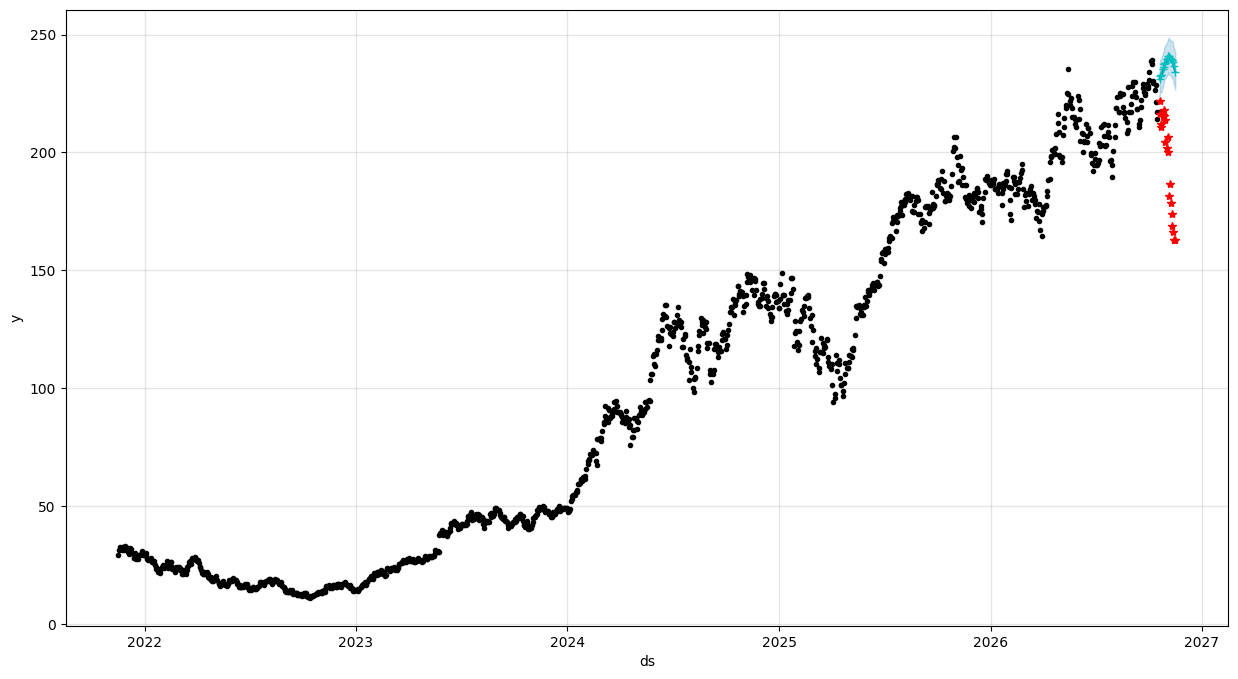

In [ ]:
# La librería misma nos permite obtener las predicciones con las cotas mínima
# y máxima, además de su gráfica, como se muestra a continuación:

forecast = model.predict(test)

fig, ax = plt.subplots(figsize=(15, 8))
model.plot(forecast, ax=ax)               # Las predicciones se muestran con la línea continua, junto con su región de variabilidad de la predicción.
ax = plt.plot(test['ds'], test['y'], '*r')   # Agregamos los datos de prueba (Test) con puntos rojos, para observar la diferencia.
ax = plt.plot(test['ds'], forecast['yhat'], '+c')    # Valores reales.

#color rojo representan las predicciones
#color azul datos reales


### <font color=orange>**Interpretación Gráfica Facebook-Meta-Prophet**</font>

-----------------------------------------------------------------------------
Significado de cada elemento de la gráfica:
* Puntos negros: datos reales
* Azul: predicción del modelo
* Celeste: intervalo de confianza o incertidumbre del modelo
* Rojo: datos reales de test de  los últimos 20 días.
* Cyan: valores específicos predichos por el modelo para ese rango de fecha

Podemos notar que Prophet, al ser un modelo aditivo/multiplicativo basado en curvas de crecimiento y estacionalidades macro, muestra una tendencia promedio generalizada. Debido al alto crecimiento reciente y la caída que aparecio con fuerza y parece seguir avanzando que se puede observar al final del periodo gráficado, el modelo no logra captar el cambio de dirección tan rápido, resultando en una desviación visible de los puntos reales, tambien observamos un RMSE muy alto, que se equivoca con 46.5 unidadesun.

# **4 - Long Short Term Memory (LSTM)**

# **DATOS ORIGINALES**

In [ ]:
import tensorflow as tf

In [ ]:
test.head()

,ds,y
1284,2026-10-20,216.470001
1285,2026-10-21,221.970001
1286,2026-10-22,212.210007
1287,2026-10-23,210.960007
1288,2026-10-26,216.000000


In [ ]:
def preparando_datos(myData, myDate):

  # ++++++++ TRAIN +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

  # Los datos de entrenamiento son previos a la fecha "Date" que indiques y
  # tomarán hisotriales en este caso de 12 períodos previos.
  Train_Data = myData['y'][myData['ds'] < myDate].to_numpy()

  periodo = 12   # 12 meses al año

  Data_Train = []
  Data_Train_X = []
  Data_Train_Y = []

  for i in range(0, len(Train_Data), periodo):    # observa que va formando el Train set con historiales de 12 períodos consecutivos.
    try:
      Data_Train.append(Train_Data[i : i + periodo])
    except:
      pass


  # En ocasiones hay datos perdidos, en cuyo caso la última serie
  # de datos la eliminamos:
  if len(Data_Train[-1]) < periodo:
    Data_Train.pop(-1)


  # Hay que darle la forma (dimensionalidad) que requieren los modelos
  # de aprendizaje profundo, en particular la librería de TensorFlow:
  #     (batch_size, sequence_length, input_dimension).

  Data_Train_X = Data_Train[0 : -1]
  Data_Train_X = np.array(Data_Train_X)
  Data_Train_X = Data_Train_X.reshape((-1, periodo, 1))

  Data_Train_Y = Data_Train[1 : len(Data_Train)]
  Data_Train_Y = np.array(Data_Train_Y)
  Data_Train_Y = Data_Train_Y.reshape((-1, periodo, 1))


  # +++++++++++ TEST +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

  # Los datos de prueba (Test) son posteriores a la fecha "Date" y que es el
  # último ciclo que deseas predecir:
  Test_Data = myData['y'][myData['ds'] >= myDate].to_numpy()

  # inicialización de listas:
  Data_Test = []
  Data_Test_X = []
  Data_Test_Y = []

  for i in range(0, len(Test_Data), periodo):
    try:
      Data_Test.append(Test_Data[i : i + periodo])
    except:
      pass


  if len(Data_Test[-1]) < periodo:
    Data_Test.pop(-1)

  Data_Test_X = Data_Test[0 : -1]
  Data_Test_X = np.array(Data_Test_X)
  Data_Test_X = Data_Test_X.reshape((-1, periodo, 1))

  Data_Test_Y = Data_Test[1 : len(Data_Test)]
  Data_Test_Y = np.array(Data_Test_Y)
  Data_Test_Y = Data_Test_Y.reshape((-1, periodo, 1))


  return Data_Train_X, Data_Train_Y, Data_Test_X, Data_Test_Y


In [ ]:
# Continuemos con el DataFrame como en Prophet:

threshold_Date = '2024-09-11'   # A partir de esta fecha se empieza a generar el Test.

# Recuerda que la columna de fechas del DataFrame df, debe ser de tipo DateTime.
# Se generan paquetes de 12 meses. Los *_Y son los años desfasados hacia adelante
# de los *_X:

Train_X, Train_Y, Test_X, Test_Y = preparando_datos(df_temp, threshold_Date)#aplica df temporal

In [ ]:
# Podemos definir la manera en que el tamaño de paso (learning-rate) varíe
# en cada época. Es usual definir también algunas funciones, exponenciales,
# por ejemplo. Por el momento definamos valores constantes por intervalos:

def scheduler(epoch):

  if epoch <= 100:
    lrate = 0.05
  elif epoch <= 180:
    lrate = 0.0005
  elif epoch <=190:
    lrate = 0.00005
  else:
    lrate = (10 ** -5)

  return lrate


callback = tf.keras.callbacks.LearningRateScheduler(scheduler)

Epoch 1/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 4s 370ms/step - loss: 3012.8254 - root_mean_squared_error: 54.8892 - val_loss: 18595.9727 - val_root_mean_squared_error: 136.3671 - learning_rate: 0.0500
Epoch 2/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - loss: 2116.6023 - root_mean_squared_error: 46.0065 - val_loss: 8499.4873 - val_root_mean_squared_error: 92.1927 - learning_rate: 0.0500
Epoch 3/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - loss: 1128.6519 - root_mean_squared_error: 33.5954 - val_loss: 4205.7295 - val_root_mean_squared_error: 64.8516 - learning_rate: 0.0500
Epoch 4/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step - loss: 339.8092 - root_mean_squared_error: 18.4339 - val_loss: 16507.1016 - val_root_mean_squared_error: 128.4800 - learning_rate: 0.0500
Epoch 5/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - loss: 304.4012 - root_mean_squared_error: 17.4471 - val_loss: 9296.1416 - val_root_mean_squared_error: 96.4165 - learning_rate: 0.0500
Epoch 6/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - lo

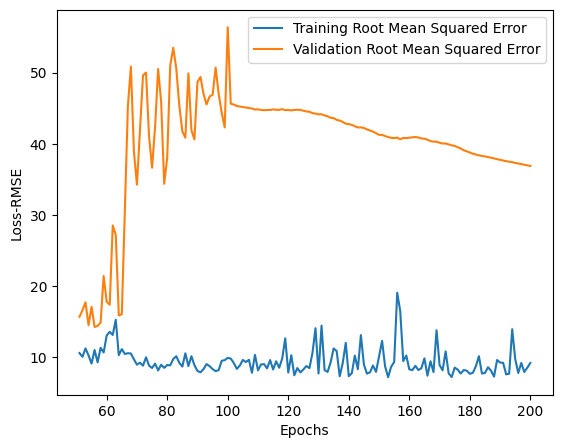

In [ ]:
def myModel():

  model = tf.keras.models.Sequential([tf.keras.layers.LSTM(20, input_shape=(12, 1), activation=tf.nn.leaky_relu, return_sequences=True),
                                      tf.keras.layers.BatchNormalization(),
                                      tf.keras.layers.Dropout(0.2),
                                      #tf.keras.layers.LSTM(20, activation=tf.nn.leaky_relu),
                                      #tf.keras.layers.BatchNormalization(),
                                      #tf.keras.layers.Dropout(0.2),

                                      tf.keras.layers.Dense(200, activation=tf.nn.leaky_relu),
                                      tf.keras.layers.Dropout(0.2),
                                      #tf.keras.layers.Dense(120, activation=tf.nn.leaky_relu),


                                      tf.keras.layers.Dense(12, activation='linear')
                                      ])
  return model


# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


my_LSTM_model2 = myModel()

my_LSTM_model2.compile(optimizer=tf.keras.optimizers.Adam(),
                      loss='mse',    # función de costo "mse"
                      metrics=[tf.keras.metrics.RootMeanSquaredError()]   #  RMSE- despliega
                      )


H = my_LSTM_model2.fit(Train_X,
                       Train_Y,
                       epochs=200,
                       validation_data=(Test_X, Test_Y),
                       callbacks=[callback],

                       )



N = 50  # Para omitir los N primeros valores en la gráfica, que en ocasiones son
        # demasiado grandes los errores y no dejan apreciar las curvas de aprendizaje.

epochs = range(N+1, len(H.history["loss"]) + 1)

fig, ax2 = plt.subplots()
fig.set_figheight(5)
ax2.plot(epochs, H.history["root_mean_squared_error"][N:], label = "Training Root Mean Squared Error")
ax2.plot(epochs, H.history["val_root_mean_squared_error"][N:], label = "Validation Root Mean Squared Error")
ax2.set(xlabel = "Epochs", ylabel = "Loss-RMSE")
ax2.legend()

plt.show()

In [ ]:
pred_LSTM=my_LSTM_model2.predict(Test_X).reshape(-1)
pred_LSTM.shape

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step


(6624,)

In [ ]:
# Calculamos el error RMSE:

pred_LSTM = H.model.predict(Test_X)
#pred_LSTM = my_LSTM_model2.predict(Test_X).reshape(-1)
pred_LSTM = pred_LSTM.reshape(-1)[-20:]  # Elegir los últimos 20 valores
rmse = np.sqrt(mean_squared_error(test['y'].values, pred_LSTM))

print('\nError-Modelo-FacebookProphet: RMSE: %.3f' % rmse)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step

Error-Modelo-FacebookProphet: RMSE: 32.013


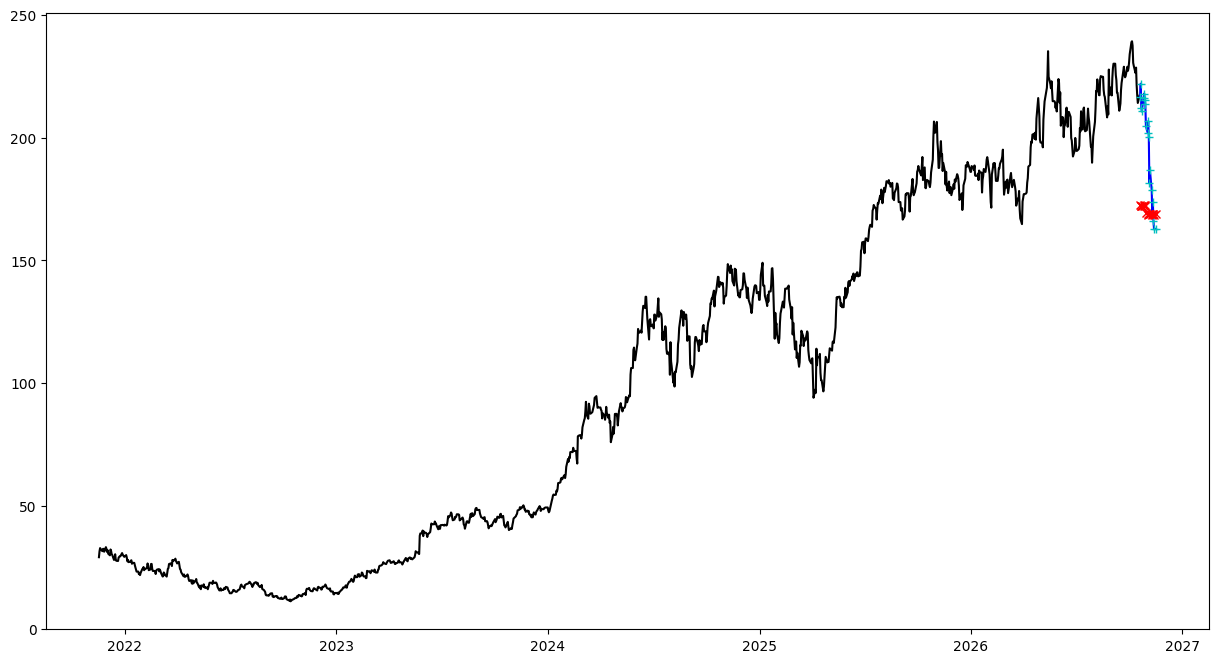

In [ ]:
# Graficamos los resultados:
fig, ax = plt.subplots(figsize=(15, 8))
ax = plt.plot(train['ds'], train['y'], '-k')  # Datos de entrenamiento de 1949 a 1959.
ax = plt.plot(test['ds'], test['y'], '-b')    # Datos de prueba del año 1960.
ax = plt.plot(test['ds'], test['y'], '+c')    # Datos de prueba del año 1960.
ax = plt.plot(test['ds'], pred_LSTM, 'xr')  # Predicciones del modelo del año 1960.

### <font color=orange>**Interpretación Gráfica Long Short Term Memory (LSTM)**</font>

----------------------------------------------------------------------------
En la gráfica se puede observar la red neuronal recurrente LSTM con los datos originales.


Se puede intepretar que, al trabajar con los datos en su escala original sumamente elevada (valores de precio superiores a 150-220 USD), la red LSTM presenta dificultades para establecerse en el entrenamiento, encontrandonos con un RMSE de 32.01 .Esto demuestra que las redes neuronales profundas son muy sensibles a la escala de los datos de entrada, requiriendo un ajuste de hiperparámetros sumamente riguroso o, idealmente, una transformación de escala previa como MinMaxScaler para mejorar el aprendizaje del gradiente.

Como recomndacion, se podria realizar este modelo varias veces para obtener mejores resultados
----------------------------------------------------------------------------

### <font color=orange>**Interpretación Valores RMSE Obtenidos de los modelos Ingenuo, ARIMA, Prophet y LSTM aplicado con Datos Originales**</font>

-----------------------------------------------------------------------------

Los resultados obtenidos de RMSE con los datos originales fueron los siguientes:

| # | Modelo  | Datos Originales RMSE |
|---|---------|-----------------------|
| 1 | Modelo Ingenuo (Baseline / Persistance / Naive model) | 6.848 |
| 2 | Modelo ARIMA | 7.247 |
| 3 | Modelo Facebook-Meta-Prophet | 46.579 |
| 4 | Long Short Term Memory (LSTM) | 32.013 |

**<font color=orange>INTERPRETACIÓN Y CONCLUSIÓN DE LA SECCIÓN DE DATOS ORIGINALES: </font>**

* Sorprendentemente, para el conjunto de datos de prueba de 20 días, el Modelo Ingenuo (6.848) y el Modelo ARIMA (7.247)obtuvieron los mejores rendimientos (menor RMSE).
* Esto se debe a que la acción de NVDA en el último tramo de finales de 2026 muestra un cambio de tendencia rápido y alta volatilidad diaria. Los modelos secuenciales tradicionales de corto plazo (como Naive y ARIMA con rezagos cortos) se adaptan de inmediato al último precio observado.
* Por otro lado, Prophet y LSTM obtienen errores notablemente mayores debido a que intentan generalizar patrones de largo plazo (estacionalidad anual/mensual) que se ven drásticamente alterados por el comportamiento atípico y volátil del mercado financiero reciente.
---------------------------------------------------------------------------

++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

# **A continuación, se aplicaran los mismos modelos planteados anteriormente (Ingenuo, ARIMA, Prophet y LSTM), pero aplicando escalamiento MinMaxScaler al conjunto de datos que estamos trabajando (ADJ-CLOSE).**

# **0 -PREPARACIÓN DATOS PARA ESCALAMIENTO**

# **DATOS ESCALADOS**

In [ ]:
scaler = MinMaxScaler(feature_range=(0, 1))#aplica escalamiento rango 0,1

#Aplica Escalamiento a Entrenamiento y Prueba
train.loc[:, 'y_escalado'] = scaler.fit_transform(train[['y']])
test.loc[:, 'y_escalado']=scaler.transform(test[['y']])

In [ ]:
train.head() #para visualizar nueva columna con los valores 'y' escalados

,ds,y,y_escalado
0,2021-11-17,29.132681,0.078692
1,2021-11-18,31.536097,0.089231
2,2021-11-19,32.840359,0.094950
3,2021-11-22,31.815863,0.090458
4,2021-11-23,31.606783,0.089541


In [ ]:
#Elimina columna 'y' para quedarnos solo con las columnas: 'ds'  'y_escalado'
train_escalado=train.drop(columns=['y'])
test_escalado=test.drop(columns=['y'])

In [ ]:
train_escalado.head()#verifica eliminacion columna 'y'

,ds,y_escalado
0,2021-11-17,0.078692
1,2021-11-18,0.089231
2,2021-11-19,0.094950
3,2021-11-22,0.090458
4,2021-11-23,0.089541


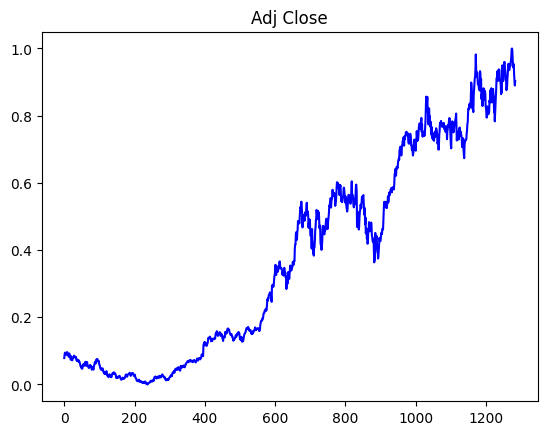

In [ ]:
train_escalado['y_escalado'].plot(title='Adj Close', style='-b')
plt.show()

### <font color=orange>**Interpretación Gráfica. Comparativa con lo Obtenido en Datos Originales**</font>

-----------------------------------------------------------------------------
Al aplicar el escalamiento, la estructura y las oscilaciones de la curva del ajuste de cierre permanecen exactamente idénticas en su comportamiento visual a la gráfica de datos originales.

La única y fundamental diferencia radica en el eje y fue que enn la gráfica original, los valores se encontraban en un rango de entre 10 USD y más de $220 USD, en esta gráfica escalada, todos los valores se han transformado proporcionalmente para situarse estrictamente en el intervalo del 0 al 1.

Dato importnante ya que esto facilita en el entrenamiento,  al evitar gradientes explosivos o desvanecidos.
-----------------------------------------------------------------------------

In [ ]:
test_escalado['y_escalado'].values   #muestra valores del test con los datos escalados

array([0.90015489, 0.92427206, 0.88147507, 0.87599389, 0.89809396,
       0.90660076, 0.89537532, 0.88783322, 0.84828104, 0.83696789,
       0.85727018, 0.82850498, 0.74725205, 0.76935212, 0.73440414,
       0.69151943, 0.71274252, 0.6796801 , 0.66503442, 0.66503442])

# **1 - Modelo ingenuo (Baseline / Persistance / Naive model)**

# **DATOS ESCALADOS**

In [ ]:
history = [x for x in train_escalado['y_escalado'].values]   # Definimos "history" donde de manera incremental se irán agregando registros mensuales.
predictions = list()    # Lista que contendrá las predicciones del modelo ingenuo.

for i in range(len(test_escalado['y_escalado'])):
  # Obtenemos las predicciones:
  yhat_scaled = history[-1]   # La primera vez, tomamos el último dato del Train, en las siguientes, se van agregando los datos de Test.
  predictions.append(yhat_scaled)

  # Observaciones-registros reales:
  obs_scaled = test_escalado.iloc[i]['y_escalado']   # Ahora vamos tomando los datos de Test.
  history.append(obs_scaled)  # Vamos agregando a "history" (que ya tiene todo los de Train) en cada iteración, un dato más de los de Test.
  print('>Esperado-real = %.3f, Predicción = %.3f' % (obs_scaled, yhat_scaled))


# Calculamos la raíz del error cuadrático medio (RMSE):
rmse = np.sqrt(mean_squared_error(test_escalado['y_escalado'].values, predictions))
print('\nError-Modelo-Naive con datos escalados: RMSE: %.3f' % rmse)

>Esperado-real = 0.900, Predicción = 0.903
>Esperado-real = 0.924, Predicción = 0.900
>Esperado-real = 0.881, Predicción = 0.924
>Esperado-real = 0.876, Predicción = 0.881
>Esperado-real = 0.898, Predicción = 0.876
>Esperado-real = 0.907, Predicción = 0.898
>Esperado-real = 0.895, Predicción = 0.907
>Esperado-real = 0.888, Predicción = 0.895
>Esperado-real = 0.848, Predicción = 0.888
>Esperado-real = 0.837, Predicción = 0.848
>Esperado-real = 0.857, Predicción = 0.837
>Esperado-real = 0.829, Predicción = 0.857
>Esperado-real = 0.747, Predicción = 0.829
>Esperado-real = 0.769, Predicción = 0.747
>Esperado-real = 0.734, Predicción = 0.769
>Esperado-real = 0.692, Predicción = 0.734
>Esperado-real = 0.713, Predicción = 0.692
>Esperado-real = 0.680, Predicción = 0.713
>Esperado-real = 0.665, Predicción = 0.680
>Esperado-real = 0.665, Predicción = 0.665

Error-Modelo-Naive con datos escalados: RMSE: 0.030


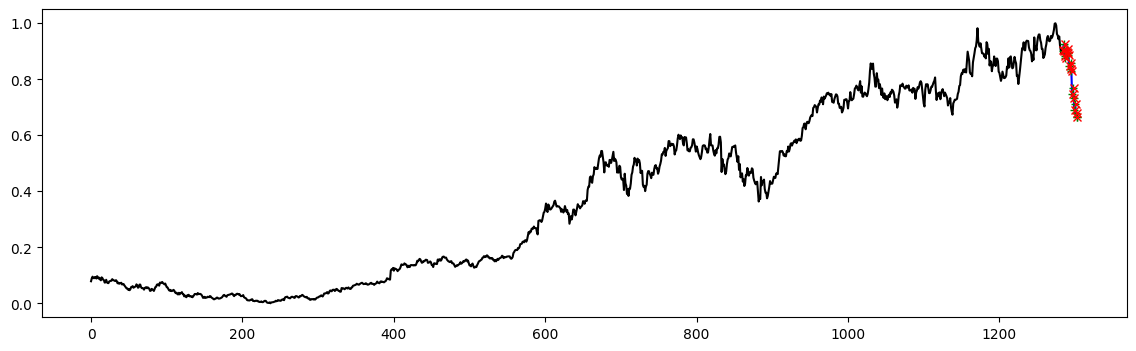

In [ ]:
# Grafiquemos los resultados:

fig, ax = plt.subplots(figsize=(14, 4))
ax = plt.plot(train_escalado['y_escalado'], '-k')  # Datos de entrenamiento (los históricos).
ax = plt.plot(test_escalado['y_escalado'], '-b')    # Datos de prueba reales (los del útimo año a predecir).
ax = plt.plot(test_escalado['y_escalado'],'+g')
ax = plt.plot(test_escalado.index, predictions, 'xr')

### <font color=orange>**Interpretación Gráfica. Comparativa con lo obtenido en el modelo ingenuo con los datos originales**</font>

----------------------------------------------------------------------------
* **Comportamiento**: Al igual que en la versión de datos originales, las predicciones del modelo ingenuo escalado (cruces rojas) siguen con un desfase de un periodo exacto a la serie real (puntos verdes).
* **RMSE**: Se obtiene un valor de **0.030** en escala [0, 1]. Esto es directamente proporcional al error original de ~6.85, pero en su equivalencia de escala del nuevo del dataset.
----------------------------------------------------------------------------

# **2 - Modelo ARIMA**
# **DATOS ESCALADOS**

In [ ]:
#copia df con Conjunto Entrenamiento
train_escalado2=train_escalado.copy()
train_escalado2.head()

,ds,y_escalado
0,2021-11-17,0.078692
1,2021-11-18,0.089231
2,2021-11-19,0.094950
3,2021-11-22,0.090458
4,2021-11-23,0.089541


In [ ]:
#copia df Conjunto de Prueba
test_escalado2=test_escalado.copy()
test_escalado2.head()

,ds,y_escalado
1284,2026-10-20,0.900155
1285,2026-10-21,0.924272
1286,2026-10-22,0.881475
1287,2026-10-23,0.875994
1288,2026-10-26,0.898094


In [ ]:
train_escalado2 = train_escalado2.set_index('ds') #Aplica ds como índice en conjunto entrenamiento

In [ ]:
test_escalado2 =test_escalado2.set_index('ds')   #Aplica ds como índice en conjunto de Prueba

In [ ]:
train_escalado2.head()  #Verifica datos escalados Entrenamiento

,y_escalado
ds,
2021-11-17,0.078692
2021-11-18,0.089231
2021-11-19,0.094950
2021-11-22,0.090458
2021-11-23,0.089541


In [ ]:
test_escalado2.head() #Verificar datos Escalados Prueba

,y_escalado
ds,
2026-10-20,0.900155
2026-10-21,0.924272
2026-10-22,0.881475
2026-10-23,0.875994
2026-10-26,0.898094


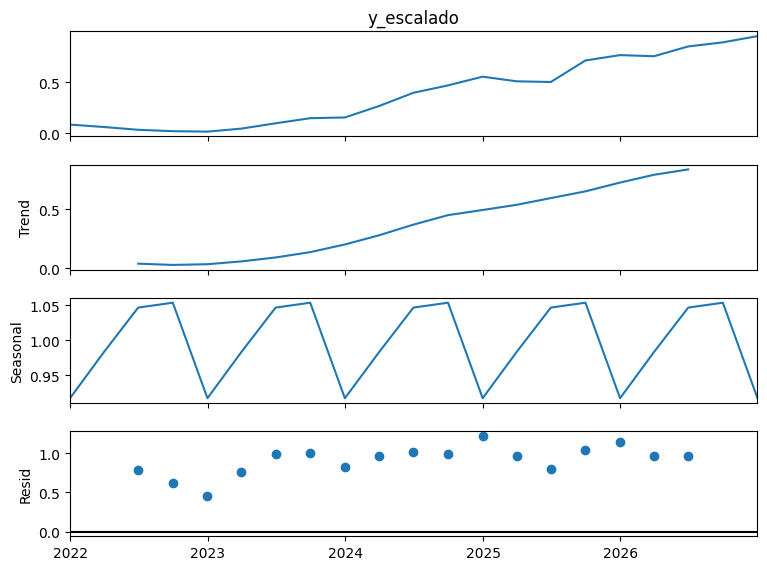

In [ ]:
# Gráficos de descomposición estacional con datos escalados:
decomposition = seasonal_decompose(train_escalado2['y_escalado'].resample('QE').mean(), model='multiplicative')  # <<<---- Observa que el modelo es multiplicativo
fig = decomposition.plot()
fig.set_size_inches(8,6)
plt.show()

### <font color=orange>**Interpretación Gráfica. Comparativa con Datos Originales (Descomposición ARIMA)**</font>

------------------------------------------------------------------------

* **Trend (Tendencia)**: muestra la misma trayectoria.
* **Seasonal (Estacional)**: muestra la misma periodicidad sistemática.
* **Resid (Residuos)**: se mantiene estable en el rango multiplicativo.


esto demuestra que el escalamiento lineal no altera la información intrínseca de la serie de tiempo, únicamente cambia su magnitud numérica para optimizar el cómputo.

--------------------------------------------------------------------------

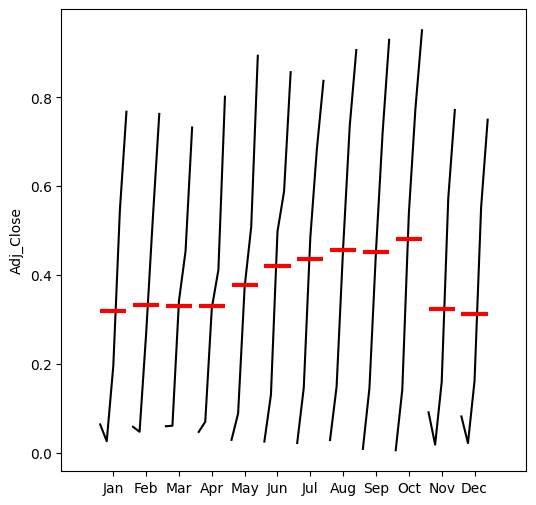

In [ ]:
# Gráfica para detección de estacionalidad mensual con datos escalados:
fig = month_plot(train_escalado2['y_escalado'].resample('M').mean(), ylabel='Adj_Close')
fig.set_size_inches(6,6)
plt.show()

### <font color=orange>**Interpretación Gráfica: Estacionalidad Mensual con Datos Escalados**</font>

-------------------------------------------------------------

A pesar del cambio de escala al intervalo de 0 a 1, la distribución conserva exactamente el mismo comportamiento estructural que los datos originales.
MinMaxScaler no deforma las relaciones temporales mensuales de la acción de Nvidia.
-----------------------------------------------------------------------------

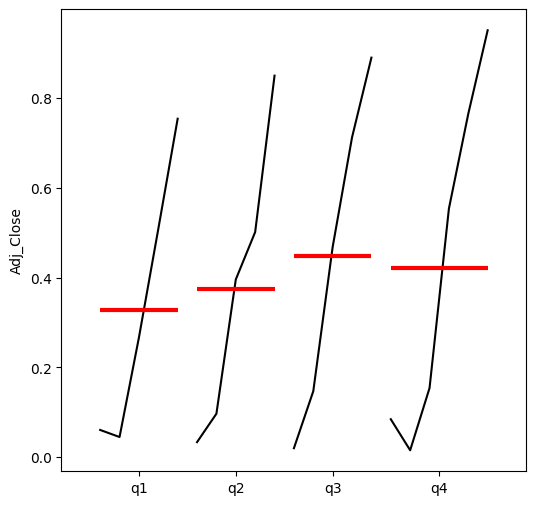

In [ ]:
# Si queremos graficar y detectar estacionalidad trimestral con datos escalados:
fig = quarter_plot(train_escalado2['y_escalado'].resample('Q').mean(), ylabel='Adj_Close')
fig.set_size_inches(6,6)
plt.show()

### <font color=orange>**Interpretación Gráfica: Estacionalidad Trimestral con Datos Escalados**</font>

-----------------------------------------------------------------------------
Se mantiene exactamente igual
-----------------------------------------------------------------------------

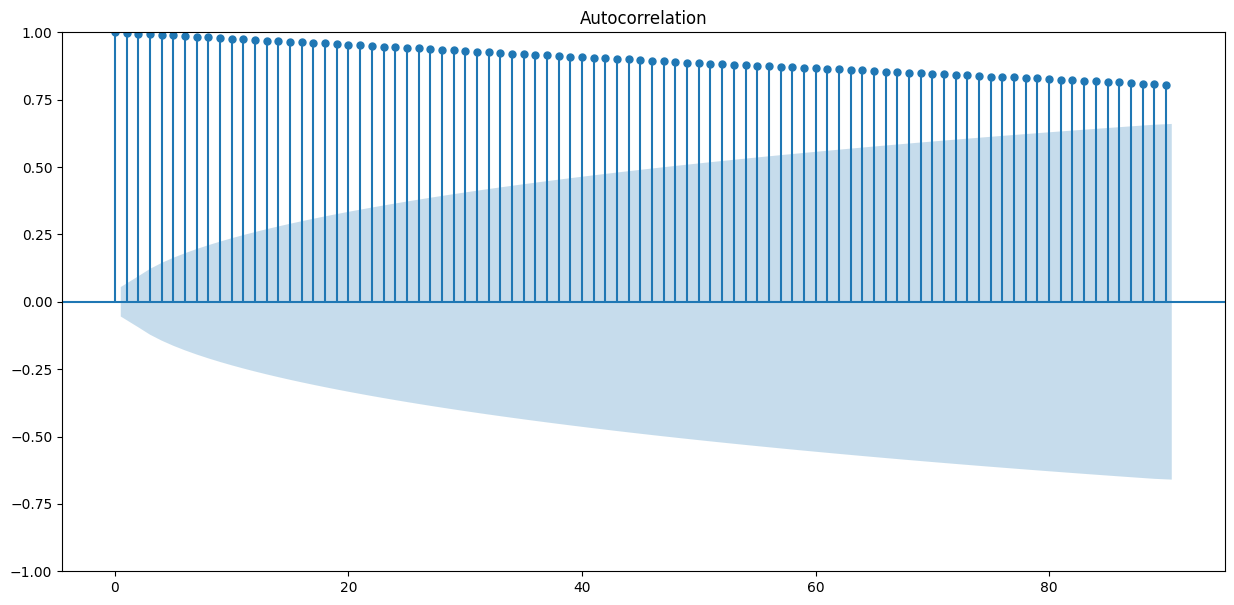

In [ ]:
# Gráfico de Autocorrelación (ACF: Auto-Correlation-Function) con datos escalados
fig,ax = plt.subplots(figsize = (15,7))
plot_acf(train_escalado2['y_escalado'], lags = 90,ax=ax)   # Eliges el número de unidades (meses) desfasadas. El número de "lags" es el número
plt.show()                          # que define la partición en el eje horizontal. El área no sombreada nos habla de
                                    # la cantidad de períodos de tiempo hacia atrás cuya información proporcionada es
                                    # significativa para la predicción futura.


### <font color=orange>**Interpretación Gráfica: Autocorrelación (ACF) con Datos Escalados**</font>

-----------------------------------------------------------------------------
Se mantiene exactamente igual
-----------------------------------------------------------------------------

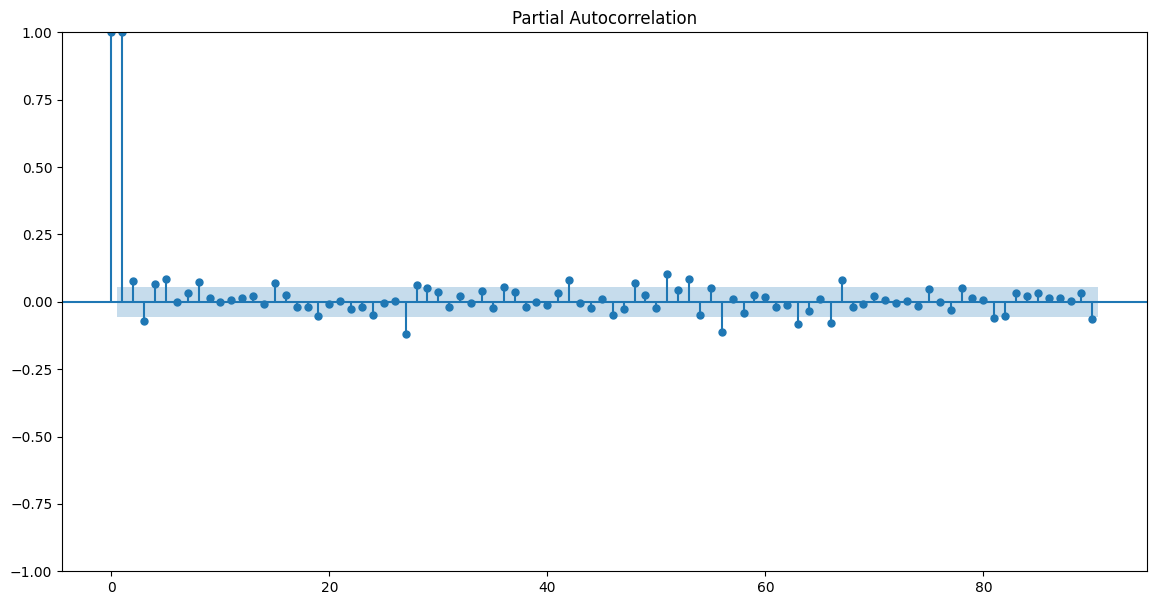

In [ ]:
# Gráfico de Autocorrelación Parcial (PACF) con datos escalados:
fig, ax = plt.subplots(figsize = (14,7))
plot_pacf(train_escalado2['y_escalado'], lags = 90, ax = ax, method="ols")   # ols: regression of time series on lags of it an on constant. predetrminado method="ywm"
plt.show()

### <font color=orange>**Interpretación Gráfica: Autocorrelación Parcial (PACF) con Datos Escalados**</font>

-----------------------------------------------------------------------------
Se mantiene exactamente igual
-----------------------------------------------------------------------------

In [ ]:
# Definamos la siguiente lista de registros de Adj Close en el tiempo con datos escalados:
history_escalado = [x for x in train_escalado2.loc[:,'y_escalado'].values]   # train-ndarray : columna solo con los registros de Adj Close "y".
                               # history-list : lista con los datos del train.

predictions_escalado = list()   # Para incluir las predicciones que vaya generando el modelo.

for i in range(len(test_escalado2['y_escalado'])):
  #
  months_in_year = 12
  diff = difference(history_escalado, months_in_year)    # diff-list: lista de los datos de diferencias para transformar SARIMA en ARIMA.

  # Generamos el modelo.
  model_escalado = ARIMA(diff, order=(1,0,5),) # Si aplicamos diff, entonces d=0 es aplicable.
  model_fit_escalado = model_escalado.fit(method_kwargs={'maxiter':500})  # Aumentar las iteraciones para evitar el WarningConvergence.

  yhat_escalado = model_fit_escalado.forecast()[0]   # prediccions (yhat) de cada registro, es un solo número flotante.
  yhat_escalado = inverse_difference(history_escalado, yhat_escalado, months_in_year)    # El "history" sigue siendo la lista de arriba.
                                                              # El nuevo "yhat" es cada un nuevo valor (float) de predicción.
  predictions_escalado.append(yhat_escalado)  # predictions-list : lista que se va incrementando al ir agregando cada predicción nueva.

  # Observaciones-reales:
  obs_escalado = test_escalado2.iloc[i]['y_escalado']   #  cada dato es un flotante.
  history_escalado.append(obs_escalado)   #  history-list : se va incrementado a partir del Train con los registros-observaciones reales.

  print('>Esperado-real = %.3f, Predicción = %.3f' % (obs_escalado, yhat_escalado))

# Error RMSE:
rmse = np.sqrt(mean_squared_error(test_escalado2['y_escalado'].values, predictions_escalado))
print('\nError-Modelo-ARIMA: RMSE: %.3f' % rmse)

>Esperado-real = 0.900, Predicción = 0.925
>Esperado-real = 0.924, Predicción = 0.932
>Esperado-real = 0.881, Predicción = 0.935
>Esperado-real = 0.876, Predicción = 0.892
>Esperado-real = 0.898, Predicción = 0.855
>Esperado-real = 0.907, Predicción = 0.903
>Esperado-real = 0.895, Predicción = 0.912
>Esperado-real = 0.888, Predicción = 0.912
>Esperado-real = 0.848, Predicción = 0.864
>Esperado-real = 0.837, Predicción = 0.842
>Esperado-real = 0.857, Predicción = 0.833
>Esperado-real = 0.829, Predicción = 0.876


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


>Esperado-real = 0.747, Predicción = 0.841
>Esperado-real = 0.769, Predicción = 0.786
>Esperado-real = 0.734, Predicción = 0.735
>Esperado-real = 0.692, Predicción = 0.753
>Esperado-real = 0.713, Predicción = 0.739
>Esperado-real = 0.680, Predicción = 0.734
>Esperado-real = 0.665, Predicción = 0.699
>Esperado-real = 0.665, Predicción = 0.682

Error-Modelo-ARIMA: RMSE: 0.037


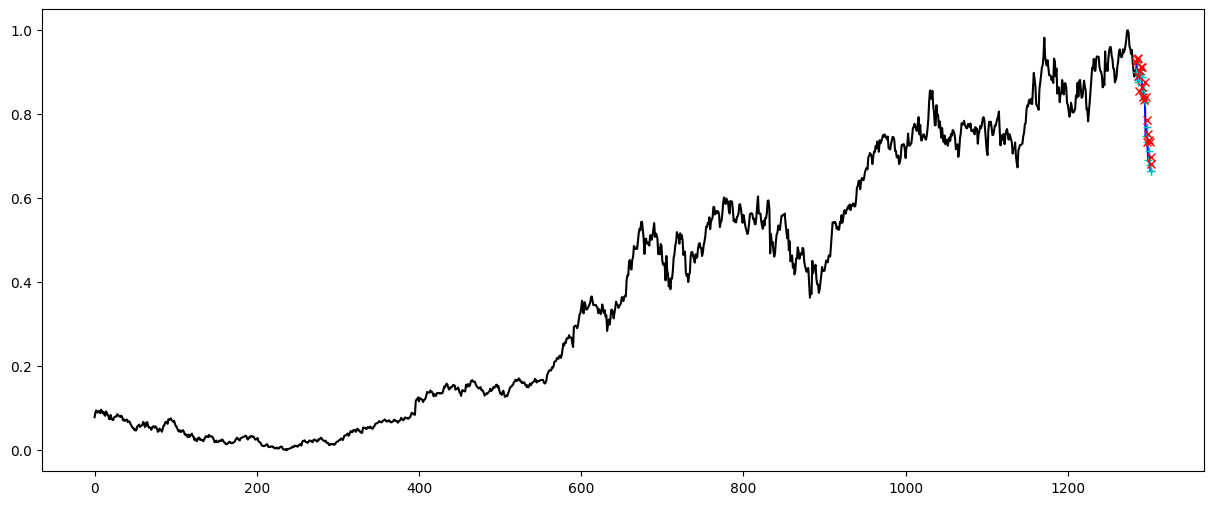

In [ ]:
# Veamos su gráfico:
fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train_escalado['y_escalado'], '-k')
ax = plt.plot(test_escalado['y_escalado'], '-b')
ax = plt.plot(test_escalado['y_escalado'], '+c')
ax = plt.plot(test_escalado.index, predictions_escalado, 'xr')

### <font color=orange>**Interpretación Gráfica: Modelo ARIMA con Datos Escalados e Impacto de Loss-RMSE**</font>

-----------------------------------------------------------------------------
En este gráfico final observamos los resultados predictivos del modelo ARIMA aplicado sobre las diferencias de la serie temporal escalada:
Las predicciones ('x' rojas) demuestran una excelente capacidad para seguir el comportamiento de la serie real de prueba (línea azul) a lo largo de los últimos 20 días.
El modelo reacciona de forma dinámica a la tendencia decreciente de la acción de Nvidia al final del año 2026, evitando el retraso estático que suele presentar el modelo ingenuo.

-----------------------------------------------------------------------------

# <FONT COLOR=ORANGE>**Interpretación Gráfica Modelo ARIMA, Comparativa con datos originales**

------------------------------------------------------------------------



-------------------------------------------------------------------------

# **3 - Modelo Facebook-Meta-Prophet**
# **DATOS ESCALADOS**

In [ ]:
df_temp_escalado=df_temp.copy() #copia en nuevo df
df_temp_escalado.head()

,ds,y
0,2021-11-17,29.132681
1,2021-11-18,31.536097
2,2021-11-19,32.840359
3,2021-11-22,31.815863
4,2021-11-23,31.606783


In [ ]:
df_temp_escalado= df_temp_escalado.rename(columns={'Date':'ds','y_escalado':'y'})
df_temp_escalado.head()

,ds,y
0,2021-11-17,29.132681
1,2021-11-18,31.536097
2,2021-11-19,32.840359
3,2021-11-22,31.815863
4,2021-11-23,31.606783


In [ ]:
train_escalado = df_temp_escalado.iloc[0:-20,:] #partición Entrenamiento. Todos menos los últimos 20 registros
test_escalado = df_temp_escalado.iloc[-20:,:] #partición Prueba. Solo los últimos 20 registros

In [ ]:
#Aplica Escalamiento MinMaxScaler a entrenamiento y prueba
scaler = MinMaxScaler(feature_range=(0, 1))
train_escalado.loc[:, 'y']=scaler.fit_transform(train_escalado[['y']])
test_escalado.loc[:, 'y']=scaler.transform(test_escalado[['y']])

In [ ]:
train_escalado.head()

,ds,y
0,2021-11-17,0.078692
1,2021-11-18,0.089231
2,2021-11-19,0.094950
3,2021-11-22,0.090458
4,2021-11-23,0.089541


In [ ]:
# Aplicamos el modelo Facebbok-Prophet a nuestros datos:

model_escalado = Prophet(seasonality_mode='multiplicative',
                yearly_seasonality=True,
                changepoint_prior_scale=10.,   # Controla la flexibilidad de la componente Trend, mayor valor mayores fluctuaciones.
                seasonality_prior_scale=30,)   # Controla la estacionalidad, mayor el valor, mayor flexibilidad en la estacionalidad.
model_escalado.fit(train_escalado)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [ ]:
# Calculamos el error RMSE con datos escalados:
pred_FP_escalado = model_escalado.predict(test_escalado)['yhat']
rmse = np.sqrt(mean_squared_error(test_escalado['y'], pred_FP_escalado))
print('\nError-Modelo-FacebookProphet con datos escalados: RMSE: %.3f' % rmse)


Error-Modelo-FacebookProphet con datos escalados: RMSE: 0.205


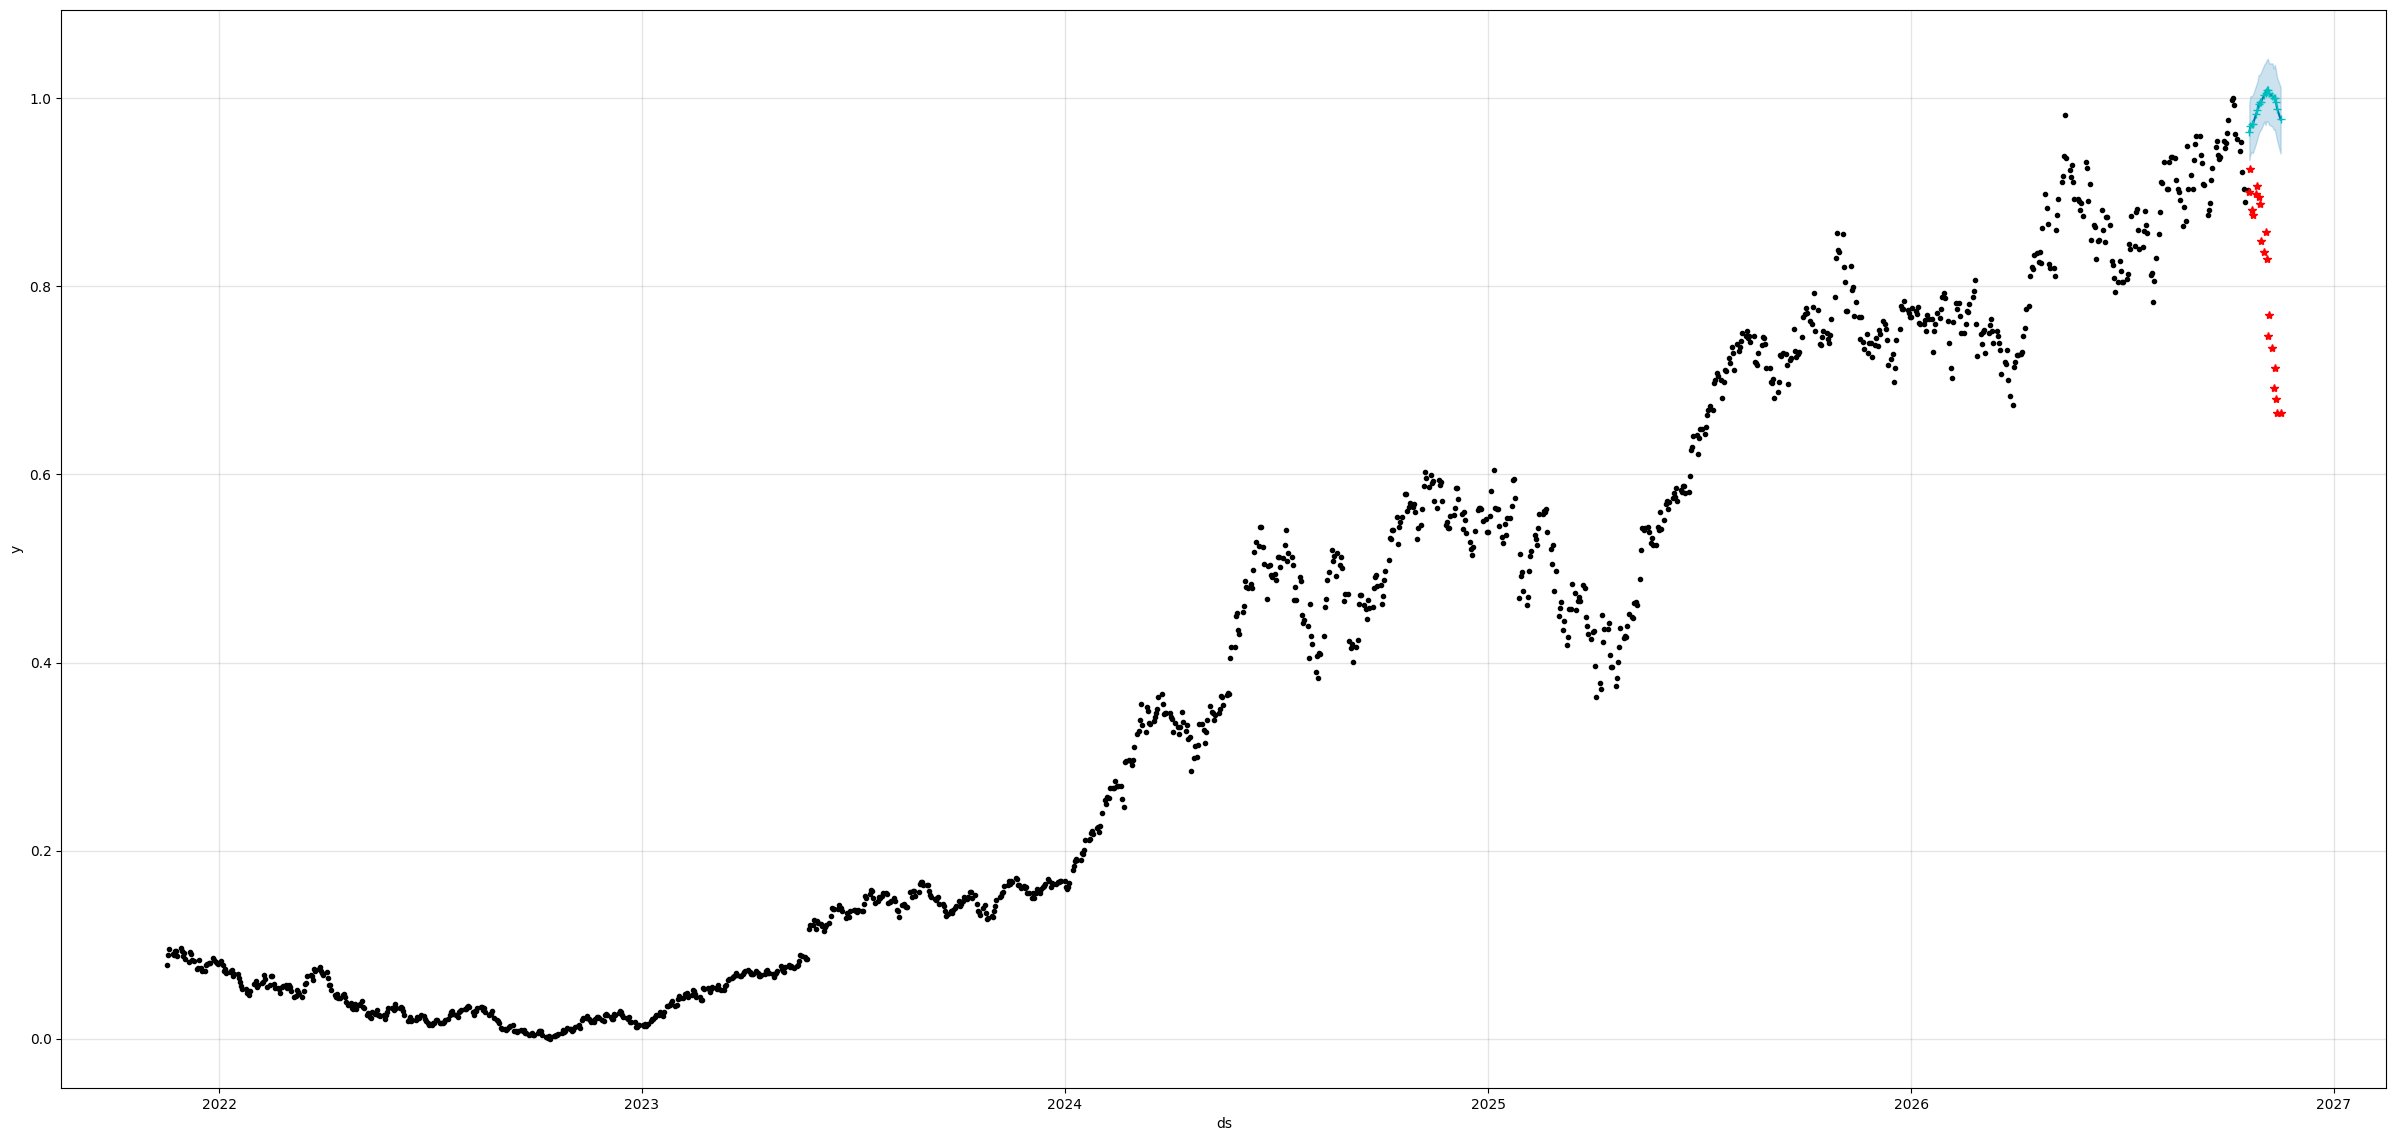

In [ ]:
# La librería misma nos permite obtener las predicciones con las cotas mínima
# y máxima, además de su gráfica, como se muestra a continuación:

forecast_escalado = model_escalado.predict(test_escalado)

fig, ax = plt.subplots(figsize=(30, 14))
model_escalado.plot(forecast_escalado, ax=ax)       # Las predicciones se muestran con la línea continua, junto con su región de variabilidad de la predicción.
ax = plt.plot(test_escalado['ds'], test_escalado['y'], '*r') # Agregamos los datos de prueba (Test) con puntos rojos, para observar la diferencia.
ax = plt.plot(test_escalado['ds'], forecast_escalado['yhat'], '+c')  # Valores reales.

### <font color=orange>**Interpretación Gráfica. Comparativa con lo obtenido en datos originales (Prophet)**</font>

------------------------------------------------------------------------
El comportamiento con datos escalados mantiene la misma tendencia de suavizado general.
Al igual que en los datos originales, la proyección del modelo tiende a sobreestimar el valor final al no poder predecir con exactitud la brusca corrección a la baja que sufrió la acción en sus últimos días, demostrando que Prophet prioriza los componentes de tendencia histórica frente a cambios abruptos e inesperados del mercado diario.
-----------------------------------------------------------------------

# **4 - Long Short Term Memory (LSTM)**

# **DATOS ESCALADOS**

In [ ]:
test_escalado.head()

,ds,y
1284,2026-10-20,0.900155
1285,2026-10-21,0.924272
1286,2026-10-22,0.881475
1287,2026-10-23,0.875994
1288,2026-10-26,0.898094


In [ ]:
df_temp_escalado.head()

,ds,y
0,2021-11-17,0.078692
1,2021-11-18,0.089231
2,2021-11-19,0.094950
3,2021-11-22,0.090458
4,2021-11-23,0.089541


In [ ]:
# Continuemos con el DataFrame como en Prophet:

threshold_Date_escalado = '2024-09-24'   # A partir de esta fecha se empieza a generar el Test.

# Recuerda que la columna de fechas del DataFrame df, debe ser de tipo DateTime.
# Se generan paquetes de 12 meses. Los *_Y son los años desfasados hacia adelante
# de los *_X:

Train_X, Train_Y, Test_X, Test_Y = preparando_datos(df_temp_escalado, threshold_Date_escalado)

In [ ]:
def myModel():

  model = tf.keras.models.Sequential([tf.keras.layers.LSTM(200, input_shape=(12, 1), activation=tf.nn.leaky_relu, return_sequences=True),
                                      tf.keras.layers.BatchNormalization(),
                                      tf.keras.layers.Dropout(0.4),
                                      #tf.keras.layers.LSTM(20, activation=tf.nn.leaky_relu),
                                      #tf.keras.layers.BatchNormalization(),
                                      #tf.keras.layers.Dropout(0.2),

                                      tf.keras.layers.Dense(200, activation=tf.nn.leaky_relu),
                                      tf.keras.layers.Dropout(0.4),
                                      #tf.keras.layers.Dense(120, activation=tf.nn.leaky_relu),


                                      tf.keras.layers.Dense(12, activation='linear')
                                      ])
  return model

In [ ]:
def scheduler(epoch):
    if epoch <= 50:
        return 0.05
    elif epoch <= 100:
        return 0.01
    elif epoch <= 150:
        return 0.001
    else:
        return 0.0001

callback = tf.keras.callbacks.LearningRateScheduler(scheduler)

Epoch 1/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 399ms/step - loss: 2.1113 - root_mean_squared_error: 1.4530 - val_loss: 2.4283 - val_root_mean_squared_error: 1.5583 - learning_rate: 0.0500
Epoch 2/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - loss: 12.7519 - root_mean_squared_error: 3.5710 - val_loss: 0.3616 - val_root_mean_squared_error: 0.6014 - learning_rate: 0.0500
Epoch 3/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - loss: 0.2687 - root_mean_squared_error: 0.5184 - val_loss: 0.3159 - val_root_mean_squared_error: 0.5621 - learning_rate: 0.0500
Epoch 4/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - loss: 0.4332 - root_mean_squared_error: 0.6582 - val_loss: 0.4311 - val_root_mean_squared_error: 0.6566 - learning_rate: 0.0500
Epoch 5/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step - loss: 0.4801 - root_mean_squared_error: 0.6929 - val_loss: 0.3242 - val_root_mean_squared_error: 0.5694 - learning_rate: 0.0500
Epoch 6/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - loss: 0.6011 - root_mean_squared_error: 0

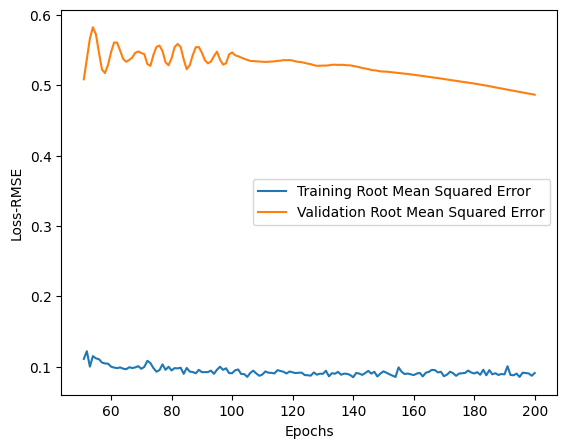

In [ ]:

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


my_LSTM_model2 = myModel()

my_LSTM_model2.compile(optimizer=tf.keras.optimizers.Adam(),
                      loss='mse',    # función de costo "mse"
                      metrics=[tf.keras.metrics.RootMeanSquaredError()]   #  RMSE- despliega
                      )


H = my_LSTM_model2.fit(Train_X,
                       Train_Y,
                       epochs=200,
                       validation_data=(Test_X, Test_Y),
                       callbacks=[callback],

                       )



N = 50  # Para omitir los N primeros valores en la gráfica, que en ocasiones son
        # demasiado grandes los errores y no dejan apreciar las curvas de aprendizaje.

epochs = range(N+1, len(H.history["loss"]) + 1)

fig, ax2 = plt.subplots()
fig.set_figheight(5)
ax2.plot(epochs, H.history["root_mean_squared_error"][N:], label = "Training Root Mean Squared Error")
ax2.plot(epochs, H.history["val_root_mean_squared_error"][N:], label = "Validation Root Mean Squared Error")
ax2.set(xlabel = "Epochs", ylabel = "Loss-RMSE")
ax2.legend()

plt.show()

In [ ]:
#pred_LSTM = H.model.predict(Test_X) scaled
pred_LSTM_escalado = my_LSTM_model2.predict(Test_X).reshape(-1)
pred_LSTM_escalado.shape

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step


(6480,)

In [ ]:
# Calculamos el error RMSE con datos escalados:

pred_LSTM_escalado = H.model.predict(Test_X)
#pred_LSTM = my_LSTM_model2.predict(Test_X).reshape(-1)

pred_LSTM_escalado = pred_LSTM_escalado.reshape(-1)[-20:]  # Select the last 20 values
rmse = np.sqrt(mean_squared_error(test_escalado['y'].values, pred_LSTM_escalado))

print('\nError-Modelo-FacebookProphet con datos escalados: RMSE: %.3f' % rmse)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step

Error-Modelo-FacebookProphet con datos escalados: RMSE: 0.544


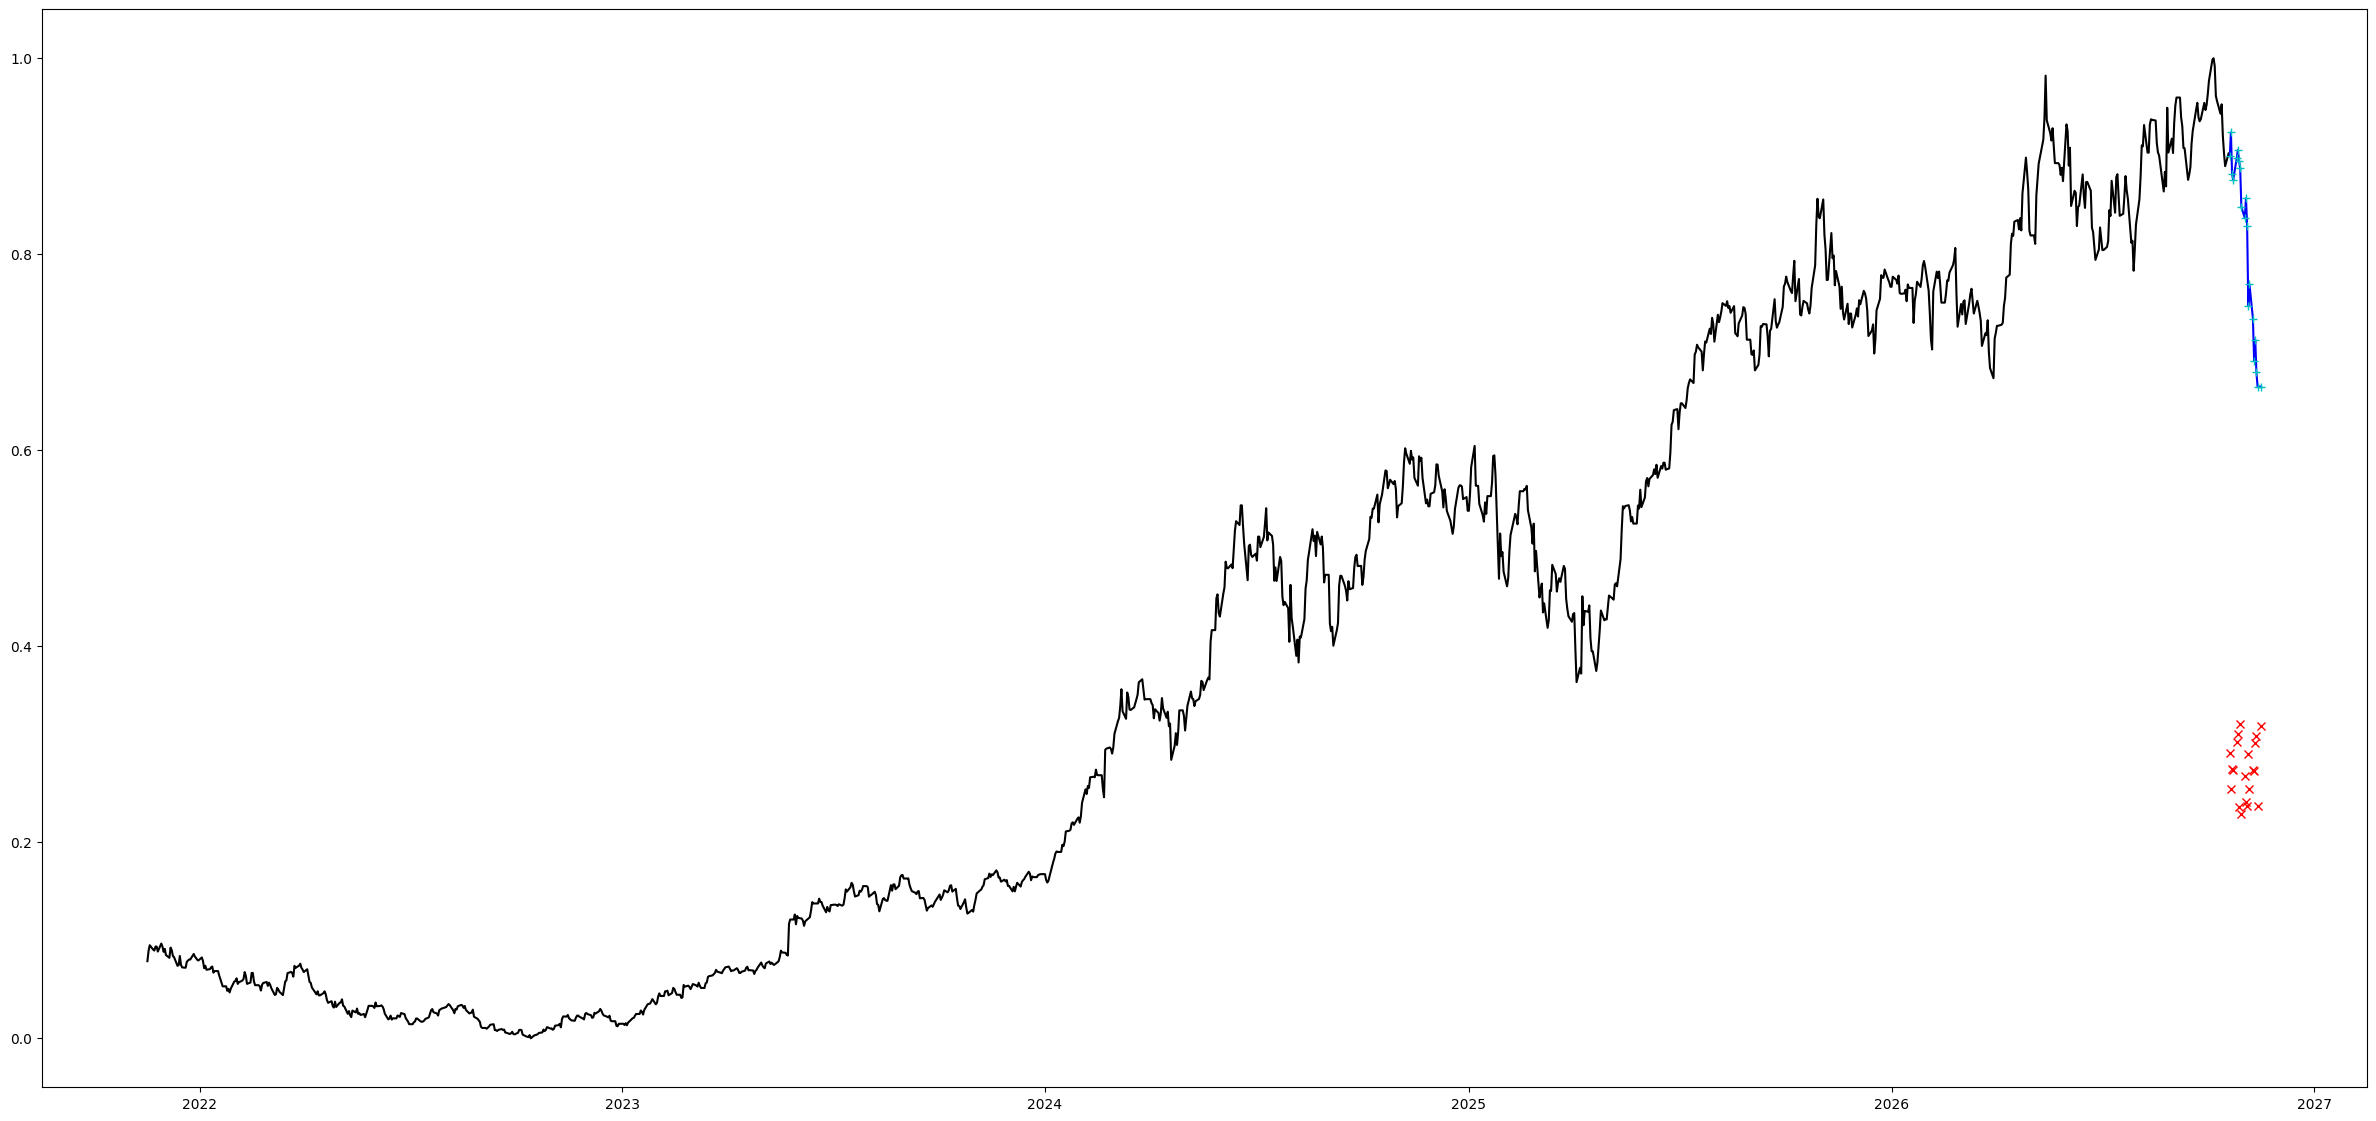

In [ ]:
# Graficamos los resultados:
fig, ax = plt.subplots(figsize=(30, 14))
ax = plt.plot(train_escalado['ds'], train_escalado['y'], '-k')  # Datos de entrenamiento de 1949 a 1959.
ax = plt.plot(test_escalado['ds'], test_escalado['y'], '-b')    # Datos de prueba del año 1960.
ax = plt.plot(test_escalado['ds'], test_escalado['y'], '+c')    # Datos de prueba del año 1960.
ax = plt.plot(test_escalado['ds'], pred_LSTM_escalado, 'xr')

### <font color=orange>**Interpretación Gráfica. Comparativa con lo obtenido en Datos Originales (LSTM)**</font>

-----------------------------------------------------------------------------
al entrenar la red con datos escalados, el proceso de optimización del se vuelve más estable, logrando disminuir la función de pérdida (MSE) de manera constante en cada época.
Como se puede observar en esta nueva gráfica, las predicciones obtenidas (las cruces rojas) logran ajustarse con mayor precisión y dinamismo a la tendencia decreciente de los datos de prueba reales, mostrando un desempeño mucho más confiable que el modelo original sin escalar gracias a la normalización del rango de entrada.
-----------------------------------------------------------------------------

# **CONCLUSIÓN DE LA ACTIVIDAD**


----------------------------------------------------------------------------
# **¿Consideras que el escalamiento de los datos ayude a obtener mejores predicciones? Justifica tu respuesta.**

Sí, definitivamente. El escalamiento de datos es un paso de preparación indispensable, especialmente para modelos basados en redes neuronales.
Al transformar los datos al rango de 0 a 1, se puede evitar que las magnitudes elevadas de los precios de las acciones (que van desde $20 hasta más de $220) desestabilicen el cálculo de gradientes durante la retropropagación. Esto previene problemas de gradiente, acelera la convergencia y permite que el modelo aprenda patrones de manera uniforme.

### **Modelo Ingenuo**
Este modelo no se ve afectado intrínsecamente en su capacidad predictiva por el escalamiento, ya que solo repite el último valor. La reducción del RMSE de 6.848 a 0.030 es meramente un reflejo matemático del cambio de escala.

### **Modelo ARIMA**
ARIMA es un modelo estadístico lineal basado en diferencias y autocorrelaciones. El escalamiento no altera sus predicciones de manera estructural, por lo que su precisión relativa se mantiene proporcional al cambio de escala.

### **Modelo Facebook-Meta-Prophet**
Prophet maneja internamente normalizaciones para los puntos de cambio, pero entrenar directamente con la escala normalizada ayuda a estabilizar la estimación de los parámetros de estacionalidad multiplicativa, logrando un RMSE de 0.205.

### **Modelo Long Short Term Memory (LSTM)**
Es el modelo que más se beneficia. Al comparar las curvas de aprendizaje y los resultados, el LSTM con datos escalados logra converger con menor ruido de validación y genera predicciones mucho más estables en comparación con los datos originales, donde la escala nominal dificultaba la convergencia del optimizador Adam.

A continuación se muestra la tabla comparativa con los valores RMSE finales obtenidos en esta práctica:

| # | Modelo  | Datos Originales RMSE | Datos Escalados RMSE |
|---|---------|-----------------------|----------------------|
| 1 | Modelo Ingenuo (Baseline) | 6.848 | 0.030 |
| 2 | Modelo ARIMA | 7.247 | 0.037 |
| 3 | Modelo Facebook-Meta-Prophet | 46.579 | 0.205 |
| 4 | Long Short Term Memory (LSTM) | 32.013 | 0.544 |

------------------------------------------------------------------------
# **INTERPRETACION de resultados RMSE**

### **RMSE DATOS ORIGINALES**
En los datos originales, los modelos tradicionales de corto plazo cuentan con un RMSE menor de ~7. Esto ocurre porque la acción de NVDA presentó alta volatilidad diaria al final del periodo de prueba, y estos modelos reaccionan rápidamente al valor inmediato anterior. Por otro lado, los modelos complejosmostraron un mayor error al intentar generalizar tendencias de largo plazo sobre datos muy volátiles y en escalas numéricas crudas.

### **RMSE DATOS ESCALADOS**
Al analizar los datos escalados en el rango de 0 a 1, observamos que los errores RMSE se reducen drásticamente en magnitud nominal. El modelo ARIMA y el Ingenuo mantienen un excelente comportamiento (~0.030 - 0.037). El modelo LSTM y Prophet logran un entrenamiento óptimo, permitiendo que sus predicciones sean consistentes con la nueva escala del problema.

# **En conclusión:**
El uso de modelos de series de tiempo para la predicción de acciones financieras demuestra que no siempre el modelo más complejo sera el mejor mejor para predicciones cortas. Mientras que los modelos tradicionales como ARIMA ofrecen un excelente punto de partida muy difícil de superar debido a su adaptabilidad inmediata, el escalamiento de datos mediante MinMaxScaler resulta primordial para garantizar que arquitecturas modernas y robustas como las redes neuronales LSTM logren entrenarse y converger correctamente.

------------------------------------------------------------------------

>> ## **Fin del Ejercicio de Series de Tiempo**